# Selección evolutiva de características mediante algoritmo genético binario frente al filtrado univariado en clasificación supervisada

## Investigación aplicada · Fronteras de la Computación Blanda

---
* **Línea de investigación:** Tema N.º 9 — Selección evolutiva de características
* **Autores:**
  * Juan José González Ríos
  * Camilo Eduardo Muñoz Albornoz

---

### Resumen del proyecto

Este cuaderno documenta y ejecuta una investigación experimental sobre la **selección evolutiva de características**, una línea que integra la computación evolutiva con el aprendizaje supervisado para abordar problemas de reducción de dimensionalidad en datos tabulares.

El estudio evalúa si un **algoritmo genético binario** —operando bajo un enfoque *wrapper* con máscaras de selección— logra reducir la cantidad de variables del conjunto de datos *Breast Cancer Wisconsin (Diagnostic)* conservando un desempeño predictivo competitivo en **F1 macro**. Para aislar el efecto de la elección de atributos, el experimento mantiene fijo un clasificador de regresión logística y contrasta el método evolutivo contra una **selección univariada** (*filter* mediante prueba ANOVA F) restringida al mismo número de variables, así como contra una línea base que utiliza las 30 características originales.

El flujo de trabajo garantiza la reproducibilidad y evita la fuga de datos mediante particiones estratificadas independientes (entrenamiento, validación y prueba) repetidas en diez semillas, incorporando además mediciones de tiempo de cómputo, estabilidad entre ejecuciones (índice de Jaccard) y un análisis de sensibilidad sobre el peso de penalización por complejidad.

## 1. Planteamiento del problema y fundamento conceptual

La selección evolutiva de características integra dos áreas fundamentales: la **computación evolutiva** y el **aprendizaje supervisado**. Mientras los modelos supervisados aprenden patrones a partir de ejemplos etiquetados, la computación evolutiva aporta mecanismos heurísticos inspirados en la selección natural para explorar espacios de búsqueda combinatorios donde los métodos exactos resultan inviables.

### El problema de la dimensionalidad y la redundancia

En conjuntos de datos tabulares, conservar la totalidad de las variables disponibles no garantiza un mejor desempeño predictivo. La presencia de atributos irrelevantes introduce ruido que favorece el sobreajuste, mientras que las variables altamente correlacionadas aportan información redundante que incrementa la complejidad del modelo sin mejorar su capacidad de generalización.

Evaluar de forma exhaustiva todos los subconjuntos posibles de $d$ características exige analizar $2^d - 1$ combinaciones. Para un conjunto de datos con $d = 30$ variables, el espacio de búsqueda asciende a $1{,}073{,}741{,}823$ subconjuntos, lo cual hace impráctica la fuerza bruta y justifica el uso de estrategias heurísticas de selección.

### Enfoques *filter* frente a *wrapper*

Para reducir la dimensionalidad manteniendo las variables originales se distinguen principalmente dos familias de métodos:

* **Métodos de filtrado (*filter*):** evalúan cada característica de manera independiente mediante criterios estadísticos univariados (como la prueba ANOVA F) antes de entrenar el clasificador. Son rápidos y deterministas, pero ignoran las interacciones entre variables y pueden retener atributos redundantes si todos presentan puntajes individuales altos.
* **Métodos envoltorio (*wrapper*):** evalúan subconjuntos completos entrenando y validando directamente el clasificador elegido. Un algoritmo genético binario opera dentro de esta familia al codificar cada candidato como una máscara de ceros y unos, permitiendo capturar sinergias y descartar redundancias a cambio de un mayor costo computacional y de variabilidad estocástica entre ejecuciones.

### Pregunta de investigación e hipótesis

* **Pregunta de investigación:** Al mantener fijo un clasificador de regresión logística sobre el conjunto de datos *Breast Cancer Wisconsin (Diagnostic)*, ¿logra un algoritmo genético binario reducir la cantidad de variables conservando un F1 macro en prueba comparable o superior al de la selección univariada con igual número de variables y al del modelo con las 30 características?
* **Hipótesis:** El algoritmo genético binario identifica subconjuntos significativamente más compactos que el conjunto completo y obtiene un F1 macro competitivo o superior frente al filtrado univariado con el mismo número de atributos, al aprovechar combinaciones entre variables; no obstante, requiere un tiempo de cómputo considerablemente mayor y exhibe cierta dispersión en las variables elegidas entre distintas semillas.

### Alcance del estudio

Este cuaderno delimita el experimento a un único conjunto de datos público, un clasificador fijo y una búsqueda evolutiva controlada. La reducción de variables sin pérdida de desempeño se trata como un resultado empírico por verificar y no como una conclusión garantizada.

## 2. Diseño y protocolo experimental

Para asegurar una comparación rigurosa y reproducible, el experimento fija todas las condiciones de evaluación antes de ejecutar las corridas finales.

### Conjunto de datos y clasificador fijo

* **Datos:** *Breast Cancer Wisconsin (Diagnostic)*, cargado directamente desde `scikit-learn` (origen: UCI Machine Learning Repository, licencia CC BY 4.0). Contiene 569 observaciones, 30 variables numéricas continuas y 2 clases (maligno y benigno).
* **Clasificador fijo:** Regresión Logística (`LogisticRegression` con `max_iter=1000` y `random_state=42`) integrada en un `Pipeline` junto con estandarización (`StandardScaler`). Mantener inalterado el clasificador en todos los experimentos garantiza que las variaciones en desempeño respondan exclusivamente al subconjunto de variables seleccionado.

### Métodos comparados

* **Método principal (Algoritmo Genético Binario):** representa cada solución como una máscara binaria $m \in \{0, 1\}^{30}$, donde cada bit indica la inclusión o exclusión de una característica. Emplea selección por torneo (tamaño 3), cruce uniforme (probabilidad $0.8$), mutación *bit-flip* (probabilidad $0.05$ por gen) y elitismo de un individuo por generación. El algoritmo maximiza en el conjunto de validación la siguiente función de aptitud:

$$\text{Fitness}(m) = (1 - \alpha)\cdot \text{F1}_{\text{macro, val}}(m) - \alpha \cdot \frac{\sum_{i=1}^{d} m_i}{d}$$

donde $d = 30$ es el total de variables y $\alpha = 0.05$ es el peso base que penaliza la complejidad del subconjunto. Se garantiza además que ninguna máscara quede completamente vacía.
* **Método de referencia (Selección univariada):** `SelectKBest` con la función estadística `f_classif` (ANOVA F). En cada semilla, el filtro selecciona exactamente el mismo número $k$ de características obtenido por el algoritmo genético, garantizando una comparación justa en igualdad de dimensionalidad.
* **Línea base contextual (Todas las variables):** el mismo clasificador fijo entrenado y evaluado utilizando las 30 características disponibles.

### Métricas, presupuesto y análisis de sensibilidad

* **Métrica principal:** F1 macro sobre el conjunto de prueba (dirección de mejora: maximizar), elegida para ponderar por igual ambas clases.
* **Métricas secundarias:** número de variables seleccionadas (minimizar), tiempo de ejecución en segundos (minimizar) y estabilidad entre ejecuciones medida mediante el índice de Jaccard promedio entre todos los pares de máscaras ganadoras obtenidas en las distintas semillas (maximizar).
* **Presupuesto y repeticiones:** el experimento ejecuta 10 semillas independientes (`0` a `9`). En cada semilla, el algoritmo genético corre con una población de 30 individuos durante 30 generaciones (máximo 900 evaluaciones de validación, optimizadas con caché de máscaras repetidas). Los métodos de referencia requieren una única evaluación por semilla.
* **Prevención de fuga de datos:** en cada semilla se genera una partición estratificada de 60 % entrenamiento, 20 % validación y 20 % prueba. El escalado y el cálculo de puntajes univariados se ajustan únicamente con entrenamiento; la función de aptitud del algoritmo genético se evalúa exclusivamente sobre validación; el conjunto de prueba se reserva para la medición final una vez elegida la máscara.
* **Análisis de sensibilidad acotado:** manteniendo fijos el dataset, el clasificador, las semillas y los operadores evolutivos, el experimento varía únicamente el parámetro de penalización $\alpha \in \{0.01, 0.05, 0.15\}$ para cuantificar el compromiso entre desempeño predictivo y reducción de variables.
* **Riesgo técnico y mitigación:** el costo acumulado de repetir diez semillas y tres niveles de sensibilidad podría elevar el tiempo de ejecución; el uso de memoria caché para máscaras repetidas y un límite acotado de iteraciones en la regresión logística mantienen la ejecución viable en un computador convencional.

## 3. Revisión de literatura y síntesis crítica

La fundamentación teórica del estudio se apoya en cinco fuentes académicas primarias arbitradas: dos investigaciones recientes (2025–2026) que muestran el estado actual de la selección evolutiva de características y tres trabajos de referencia sobre taxonomía de selección de variables, computación evolutiva y medición de estabilidad.

#### Fuente 1 — Keivanian et al. (2026)
* **Referencia y enlace:** Keivanian, F., Shafiabady, N., Noman, N., Fan, Z., & Mirjalili, S. (2026). *A fuzzy multi-objective neuro-evolutionary framework with bargaining-based selection for interpretable body fat prediction*. Neurocomputing, 675, 132974. https://doi.org/10.1016/j.neucom.2026.132974
* **Año y estado:** 2026 — Artículo arbitrado de revista.
* **Problema y método:** Aborda el equilibrio entre precisión predictiva, simplicidad e interpretabilidad mediante un marco neuroevolutivo multiobjetivo difuso con selección basada en negociación.
* **Datos y comparación:** Se evalúa en predicción de grasa corporal frente a modelos alternativos de aprendizaje automático y esquemas de selección convencionales.
* **Hallazgo y limitación:** Evidencia que optimizar simultáneamente desempeño y complejidad produce soluciones más interpretables sin degradar de forma severa el error; sin embargo, la arquitectura híbrida introduce una alta complejidad algorítmica y un elevado número de hiperparámetros que dificultan su replicación en entornos acotados.
* **Relación con la pregunta de investigación:** Funciona como antecedente metodológico reciente del compromiso entre precisión y simplicidad que este cuaderno estudia en una versión controlada mediante una función de aptitud ponderada.

#### Fuente 2 — Song et al. (2025)
* **Referencia y enlace:** Song, X., Ma, H., Zhang, Y., Gong, D., Guo, Y., & Hu, Y. (2025). *A Streaming Feature Selection Method Based on Dynamic Feature Clustering and Particle Swarm Optimization*. IEEE Transactions on Evolutionary Computation, 29(5), 1888–1902. https://doi.org/10.1109/TEVC.2024.3451688
* **Año y estado:** 2025 — Artículo arbitrado de revista.
* **Problema y método:** Estudia la selección de características en escenarios donde las variables llegan de forma continua, combinando agrupamiento dinámico de atributos con optimización por enjambre de partículas (PSO) para descartar variables irrelevantes y redundantes.
* **Datos y comparación:** Experimenta sobre 12 conjuntos de datos de distinta dificultad y un caso de aplicación real, comparando su desempeño y tiempo frente a algoritmos existentes de selección en flujo.
* **Hallazgo y limitación:** Demuestra mejoras en calidad de clasificación dentro de tiempos razonables al controlar la redundancia mediante agrupamiento; no obstante, sus resultados dependen de un escenario dinámico de llegada secuencial de atributos y requieren mecanismos adicionales que exceden el alcance de datos tabulares estáticos pequeños.
* **Relación con la pregunta de investigación:** Refuerza la vigencia de las metaheurísticas poblacionales para combatir la redundancia entre características y justifica evaluar el costo computacional junto con el desempeño predictivo.

#### Fuente 3 — Xue et al. (2016)
* **Referencia y enlace:** Xue, B., Zhang, M., Browne, W. N., & Yao, X. (2016). *A Survey on Evolutionary Computation Approaches to Feature Selection*. IEEE Transactions on Evolutionary Computation, 20(4), 606–626. https://doi.org/10.1109/TEVC.2015.2504420
* **Año y estado:** 2016 — Artículo de revisión arbitrado en revista.
* **Problema y método:** Sistematiza los enfoques de computación evolutiva aplicados a selección de características en clasificación (algoritmos genéticos, PSO, programación genética y colonia de hormigas), diferenciando representaciones binarias, funciones objetivo de un solo criterio con penalización y formulaciones multiobjetivo.
* **Datos y comparación:** Revisa de manera transversal literatura experimental en clasificación, minería de datos y selección de biomarcadores.
* **Hallazgo y limitación:** Concluye que la búsqueda global de la computación evolutiva supera frecuentemente a métodos voraces al capturar interacciones entre variables, pero advierte dos limitaciones persistentes: el alto costo de cómputo de los esquemas *wrapper* y el riesgo de sobreajuste si no se separa estrictamente la validación del conjunto de prueba.
* **Relación con la pregunta de investigación:** Fundamenta la elección de la representación mediante máscara binaria, la función de aptitud que combina F1 y tamaño del subconjunto, y el protocolo estricto de prevención de fuga de datos adoptado en este cuaderno.

#### Fuente 4 — Guyon y Elisseeff (2003)
* **Referencia y enlace:** Guyon, I., & Elisseeff, A. (2003). *An Introduction to Variable and Feature Selection*. Journal of Machine Learning Research, 3(Mar), 1157–1182. https://www.jmlr.org/papers/v3/guyon03a.html
* **Año y estado:** 2003 — Artículo arbitrado fundacional en revista.
* **Problema y método:** Establece el marco conceptual clásico de la selección de variables, definiendo las diferencias estructurales entre métodos *filter* (como el ordenamiento univariado), *wrapper* y *embedded*.
* **Datos y comparación:** Ilustra mediante ejemplos analíticos y aplicaciones en clasificación de texto y microarreglos cómo afectan la correlación, la redundancia y la complementariedad entre variables.
* **Hallazgo y limitación:** Demuestra que variables individuales con bajo poder discriminativo pueden ser altamente informativas al combinarse, y que variables muy correlacionadas no necesariamente aportan ganancia adicional; sin embargo, al ser un marco introductorio, no aborda las metaheurísticas poblacionales modernas ni sus compromisos de cómputo actuales.
* **Relación con la pregunta de investigación:** Justifica teóricamente la comparación directa entre el algoritmo genético (*wrapper*) y la selección univariada ANOVA F (*filter*) bajo igualdad en el número de características.

#### Fuente 5 — Nogueira, Sechidis y Brown (2018)
* **Referencia y enlace:** Nogueira, S., Sechidis, K., & Brown, G. (2018). *On the Stability of Feature Selection Algorithms*. Journal of Machine Learning Research, 18(174), 1–54. https://jmlr.org/papers/v18/17-514.html
* **Año y estado:** 2018 — Artículo arbitrado en revista.
* **Problema y método:** Analiza la estabilidad de los algoritmos de selección de características entendida como la consistencia de los subconjuntos elegidos frente a variaciones de muestreo y naturaleza estocástica, formalizando propiedades estadísticas deseables sobre matrices binarias de selección.
* **Datos y comparación:** Evalúa y contrasta medidas clásicas de similitud entre conjuntos (como Jaccard y Kuncheva) y propone un estimador estadístico con pruebas de hipótesis sobre conjuntos de datos de referencia.
* **Hallazgo y limitación:** Señala que evaluar únicamente la precisión predictiva resulta insuficiente porque algoritmos estocásticos o con datos redundantes pueden elegir subconjuntos muy distintos con desempeño similar; también advierte que medidas simples como Jaccard pueden verse influidas por el tamaño del subconjunto seleccionado.
* **Relación con la pregunta de investigación:** Sustenta la inclusión de la estabilidad entre las diez semillas como métrica secundaria del experimento y aporta cautela crítica al interpretar el índice de Jaccard cuando existen atributos altamente correlacionados.

---

Las cinco fuentes coinciden en que la selección de características persigue un compromiso inevitable entre **desempeño predictivo** y **simplicidad del subconjunto**. Mientras Guyon y Elisseeff (2003) establecen por qué los filtros univariados fallan al ignorar sinergias y redundancias entre atributos, Xue et al. (2016) muestran cómo la computación evolutiva aborda ese espacio combinatorio mediante búsqueda global poblacional. Los trabajos recientes de Song et al. (2025) y Keivanian et al. (2026) confirman que la línea sigue activa, desplazándose hacia esquemas híbridos, multiobjetivo y de manejo dinámico de redundancia.

No obstante, entre los estudios existen diferencias sustanciales en escala y condiciones experimentales. Las propuestas recientes operan con arquitecturas complejas, flujos dinámicos de variables o marcos neurodifusos con múltiples etapas que no permiten generalizar automáticamente sus ganancias a problemas tabulares pequeños con presupuesto reducido. Además, tanto Xue et al. (2016) como Nogueira et al. (2018) subrayan dos riesgos que suelen quedar opacados por el entusiasmo hacia la precisión: el costo computacional de los métodos *wrapper* y la inestabilidad de los subconjuntos elegidos cuando varias columnas contienen información casi equivalente.

En consecuencia, este cuaderno delimita una pregunta empírica acotada y verificable: evaluar, bajo un protocolo estricto sin fuga de datos y con un clasificador fijo, si un algoritmo genético binario sencillo justifica su mayor costo de cómputo frente a un filtro univariado clásico en un conjunto de datos con alta redundancia, midiendo simultáneamente F1 macro, número de variables, tiempo y estabilidad entre ejecuciones.

## 4. Implementación experimental y prueba piloto

### Instalación de dependencias

Esta celda instala de forma silenciosa las bibliotecas científicas requeridas para la ejecución del experimento (`numpy`, `scikit-learn` y `matplotlib`). En entornos que ya disponen de estos paquetes, el gestor verifica las instalaciones existentes sin alterar el flujo del cuaderno.
Tambiénimporta los módulos estándar y científicos del proyecto y define la estructura `Configuracion`, la cual centraliza el identificador del tema, los autores, las diez semillas de reproducibilidad, la métrica principal, las proporciones de partición y los hiperparámetros del algoritmo genético binario, incluidos los valores de penalización $\alpha$ para el estudio de sensibilidad. Al ejecutarse, imprime un resumen de la configuración activa y las versiones exactas del entorno.

In [6]:
%pip install -q numpy scikit-learn matplotlib

from dataclasses import dataclass, field
import sys
import time
import numpy as np
import sklearn
import matplotlib
import pandas as pd
from pathlib import Path
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

@dataclass
class Configuracion:
    tema: int = 9
    integrantes: tuple[str, str] = (
        "Juan José González Ríos",
        "Camilo Eduardo Muñoz Albornoz",
    )
    semillas: list[int] = field(default_factory=lambda: list(range(10)))
    metrica_principal: str = "f1_macro"
    minimizar: bool = False
    tamano_poblacion: int = 30
    generaciones: int = 30
    tamano_torneo: int = 3
    prob_cruce: float = 0.8
    prob_mutacion: float = 0.05
    alpha_base: float = 0.05
    alphas_sensibilidad: tuple[float, ...] = (0.01, 0.05, 0.15)
    proporcion_val: float = 0.20
    proporcion_prueba: float = 0.20

config = Configuracion()

print(f"Tema seleccionado: {config.tema}")
print(f"Integrantes: {config.integrantes[0]} y {config.integrantes[1]}")
print(f"Métrica principal: {config.metrica_principal} (minimizar={config.minimizar})")
print(f"Semillas configuradas: {len(config.semillas)}")
print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | scikit-learn: {sklearn.__version__} | Matplotlib: {matplotlib.__version__}")


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Tema seleccionado: 9
Integrantes: Juan José González Ríos y Camilo Eduardo Muñoz Albornoz
Métrica principal: f1_macro (minimizar=False)
Semillas configuradas: 10
Python: 3.12.6
NumPy: 2.5.5 | scikit-learn: 1.9.1 | Matplotlib: 3.11.2


### Carga del conjunto de datos y partición estratificada

Esta celda define dos funciones: `cargar_datos`, que obtiene la matriz de características, el vector de etiquetas y los nombres de las 30 variables del conjunto *Breast Cancer Wisconsin (Diagnostic)*; y `dividir_datos`, que divide los registros en subconjuntos estratificados de 60 % entrenamiento, 20 % validación y 20 % prueba según una semilla específica. La separación estricta garantiza que el conjunto de prueba permanezca aislado durante todo el proceso de selección.

In [7]:
def cargar_datos():
    conjunto = load_breast_cancer()
    return conjunto.data, conjunto.target, list(conjunto.feature_names)

def dividir_datos(X, y, semilla, proporcion_val=0.20, proporcion_prueba=0.20):
    X_temp, X_prueba, y_temp, y_prueba = train_test_split(
        X,
        y,
        test_size=proporcion_prueba,
        stratify=y,
        random_state=semilla,
    )
    proporcion_val_relativa = proporcion_val / (1.0 - proporcion_prueba)
    X_entrenamiento, X_val, y_entrenamiento, y_val = train_test_split(
        X_temp,
        y_temp,
        test_size=proporcion_val_relativa,
        stratify=y_temp,
        random_state=semilla,
    )
    return X_entrenamiento, X_val, X_prueba, y_entrenamiento, y_val, y_prueba

X_total, y_total, nombres_variables = cargar_datos()
clases, conteos = np.unique(y_total, return_counts=True)
print(f"Observaciones: {X_total.shape[0]} | Variables: {X_total.shape[1]}")
print(f"Distribución de clases: clase 0 = {conteos[0]}, clase 1 = {conteos[1]}")

Observaciones: 569 | Variables: 30
Distribución de clases: clase 0 = 212, clase 1 = 357


### Clasificador fijo, métodos de referencia y estabilidad

Esta celda implementa las funciones base compartidas por todos los métodos del experimento:

* `crear_clasificador` construye el `Pipeline` fijo compuesto por estandarización (`StandardScaler`) y regresión logística (`LogisticRegression`), evitando fuga de datos al ajustar el escalado únicamente sobre el conjunto de entrenamiento.
* `evaluar_mascara` entrena el clasificador fijo con las columnas activas de una máscara binaria y calcula el F1 macro sobre el conjunto de evaluación indicado.
* `evaluar_todas_variables` ejecuta la línea base contextual utilizando las 30 características.
* `evaluar_seleccion_univariada` ajusta el filtro `SelectKBest` (`f_classif`) únicamente sobre entrenamiento para seleccionar exactamente $k$ variables y evaluar el clasificador fijo en prueba.
* `calcular_estabilidad_jaccard` calcula el índice de Jaccard promedio entre todos los pares de máscaras binarias obtenidas a lo largo de múltiples semillas.

In [8]:
def crear_clasificador():
    return Pipeline([
        ("escalador", StandardScaler()),
        ("clasificador", LogisticRegression(max_iter=1000, random_state=42)),
    ])

def evaluar_mascara(X_entrenamiento, y_entrenamiento, X_eval, y_eval, mascara):
    modelo = crear_clasificador()
    modelo.fit(X_entrenamiento[:, mascara], y_entrenamiento)
    predicciones = modelo.predict(X_eval[:, mascara])
    return float(f1_score(y_eval, predicciones, average="macro"))

def evaluar_todas_variables(X_entrenamiento, y_entrenamiento, X_prueba, y_prueba):
    inicio = time.perf_counter()
    mascara_completa = np.ones(X_entrenamiento.shape[1], dtype=bool)
    f1_prueba = evaluar_mascara(
        X_entrenamiento, y_entrenamiento, X_prueba, y_prueba, mascara_completa
    )
    tiempo_s = time.perf_counter() - inicio
    return {
        "mascara": mascara_completa,
        "f1_prueba": f1_prueba,
        "num_variables": int(np.sum(mascara_completa)),
        "tiempo_s": tiempo_s,
        "evaluaciones": 1,
    }

def evaluar_seleccion_univariada(X_entrenamiento, y_entrenamiento, X_prueba, y_prueba, k):
    inicio = time.perf_counter()
    selector = SelectKBest(score_func=f_classif, k=k)
    selector.fit(X_entrenamiento, y_entrenamiento)
    mascara = selector.get_support()
    f1_prueba = evaluar_mascara(
        X_entrenamiento, y_entrenamiento, X_prueba, y_prueba, mascara
    )
    tiempo_s = time.perf_counter() - inicio
    return {
        "mascara": mascara,
        "f1_prueba": f1_prueba,
        "num_variables": int(np.sum(mascara)),
        "tiempo_s": tiempo_s,
        "evaluaciones": 1,
    }

def calcular_estabilidad_jaccard(mascaras):
    n = len(mascaras)
    if n < 2:
        return 1.0
    similitudes = []
    for i in range(n):
        for j in range(i + 1, n):
            interseccion = int(np.sum(mascaras[i] & mascaras[j]))
            union = int(np.sum(mascaras[i] | mascaras[j]))
            similitudes.append(interseccion / union if union > 0 else 0.0)
    return float(np.mean(similitudes))

### Método principal: algoritmo genético binario

Esta celda implementa el algoritmo evolutivo encargado de buscar subconjuntos óptimos de características. Cada individuo es una máscara booleana de longitud $d = 30$ con la restricción de contener al menos una variable activa (`asegurar_mascara_no_vacia`).

Durante la evolución, el algoritmo utiliza un diccionario de caché indexado por los bytes de cada máscara para evitar reevaluar combinaciones repetidas. En cada generación aplica elitismo (conservando el mejor individuo intacto), selección por torneo, cruce uniforme y mutación *bit-flip*. La función de aptitud se calcula exclusivamente sobre el conjunto de validación combinando F1 macro y penalización por complejidad $\alpha$. Al finalizar las generaciones, la mejor máscara encontrada se evalúa una única vez sobre el conjunto de prueba.

In [9]:
def asegurar_mascara_no_vacia(mascara, rng):
    if not np.any(mascara):
        mascara[rng.integers(0, len(mascara))] = True
    return mascara

def seleccion_torneo(poblacion, aptitudes, tamano_torneo, rng):
    indices = rng.integers(0, len(poblacion), size=tamano_torneo)
    mejor_idx = indices[np.argmax(aptitudes[indices])]
    return poblacion[mejor_idx].copy()

def cruce_uniforme(padre1, padre2, prob_cruce, rng):
    if rng.random() >= prob_cruce:
        return padre1.copy(), padre2.copy()
    mascara_cruce = rng.random(len(padre1)) < 0.5
    hijo1 = np.where(mascara_cruce, padre1, padre2)
    hijo2 = np.where(mascara_cruce, padre2, padre1)
    return hijo1, hijo2

def mutacion_bit_flip(individuo, prob_mutacion, rng):
    mutaciones = rng.random(len(individuo)) < prob_mutacion
    individuo = np.logical_xor(individuo, mutaciones)
    return asegurar_mascara_no_vacia(individuo, rng)

def algoritmo_genetico_binario(
    X_entrenamiento,
    y_entrenamiento,
    X_val,
    y_val,
    X_prueba,
    y_prueba,
    config,
    semilla,
    alpha=None,
):
    inicio = time.perf_counter()
    alpha_efectivo = config.alpha_base if alpha is None else alpha
    rng = np.random.default_rng(semilla)
    num_caracteristicas = X_entrenamiento.shape[1]

    poblacion = [
        asegurar_mascara_no_vacia(rng.random(num_caracteristicas) < 0.5, rng)
        for _ in range(config.tamano_poblacion)
    ]

    cache_aptitud = {}

    def calcular_aptitud(mascara):
        clave = mascara.tobytes()
        if clave not in cache_aptitud:
            f1_val = evaluar_mascara(
                X_entrenamiento, y_entrenamiento, X_val, y_val, mascara
            )
            proporcion = float(np.sum(mascara)) / num_caracteristicas
            aptitud = (1.0 - alpha_efectivo) * f1_val - alpha_efectivo * proporcion
            cache_aptitud[clave] = aptitud
        return cache_aptitud[clave]

    historial_mejor_aptitud = []
    mejor_mascara = None
    mejor_aptitud = -np.inf

    for _ in range(config.generaciones):
        aptitudes = np.array([calcular_aptitud(ind) for ind in poblacion])
        idx_elite = int(np.argmax(aptitudes))

        if aptitudes[idx_elite] > mejor_aptitud:
            mejor_aptitud = float(aptitudes[idx_elite])
            mejor_mascara = poblacion[idx_elite].copy()

        historial_mejor_aptitud.append(mejor_aptitud)

        nueva_poblacion = [poblacion[idx_elite].copy()]
        while len(nueva_poblacion) < config.tamano_poblacion:
            p1 = seleccion_torneo(poblacion, aptitudes, config.tamano_torneo, rng)
            p2 = seleccion_torneo(poblacion, aptitudes, config.tamano_torneo, rng)
            h1, h2 = cruce_uniforme(p1, p2, config.prob_cruce, rng)
            h1 = asegurar_mascara_no_vacia(mutacion_bit_flip(h1, config.prob_mutacion, rng), rng)
            h2 = asegurar_mascara_no_vacia(mutacion_bit_flip(h2, config.prob_mutacion, rng), rng)
            nueva_poblacion.append(h1)
            if len(nueva_poblacion) < config.tamano_poblacion:
                nueva_poblacion.append(h2)

        poblacion = nueva_poblacion

    f1_prueba = evaluar_mascara(
        X_entrenamiento, y_entrenamiento, X_prueba, y_prueba, mejor_mascara
    )
    tiempo_s = time.perf_counter() - inicio

    return {
        "mascara": mejor_mascara,
        "f1_prueba": f1_prueba,
        "mejor_aptitud_val": mejor_aptitud,
        "num_variables": int(np.sum(mejor_mascara)),
        "tiempo_s": tiempo_s,
        "evaluaciones": len(cache_aptitud),
        "historial_aptitud": historial_mejor_aptitud,
    }

### Función por semilla y prueba piloto técnica

La siguiente celda define `ejecutar_semilla`, la cual aplica el protocolo completo sobre una semilla dada: genera la partición sin fuga de datos, ejecuta primero el algoritmo genético binario, utiliza el número exacto de variables seleccionadas $k$ para ejecutar la selección univariada en igualdad de condiciones y finalmente evalúa el modelo con todas las variables. Cada medición se estructura en un diccionario compatible con el esquema de registro del proyecto.

Al final de la celda se ejecuta una prueba piloto con la semilla `0` para verificar el correcto funcionamiento de los tres métodos, comprobar los tiempos de ejecución y validar la coherencia de las métricas antes de lanzar las diez semillas completas.

In [10]:
def ejecutar_semilla(X, y, semilla, config, alpha=None, prefijo_ejecucion=1):
    alpha_efectivo = config.alpha_base if alpha is None else alpha
    X_ent, X_val, X_pru, y_ent, y_val, y_pru = dividir_datos(
        X, y, semilla, config.proporcion_val, config.proporcion_prueba
    )

    res_ag = algoritmo_genetico_binario(
        X_ent, y_ent, X_val, y_val, X_pru, y_pru, config, semilla, alpha=alpha_efectivo
    )
    k_seleccionado = res_ag["num_variables"]

    res_uni = evaluar_seleccion_univariada(X_ent, y_ent, X_pru, y_pru, k_seleccionado)
    res_todas = evaluar_todas_variables(X_ent, y_ent, X_pru, y_pru)

    registros = [
        {
            "ejecucion": f"{prefijo_ejecucion}_AG",
            "metodo": f"AG_alpha_{alpha_efectivo}",
            "instancia": "breast_cancer",
            "semilla": semilla,
            "metrica_principal": res_ag["f1_prueba"],
            "num_variables": res_ag["num_variables"],
            "tiempo_s": res_ag["tiempo_s"],
            "evaluaciones": res_ag["evaluaciones"],
            "observaciones": f"fitness_val={res_ag['mejor_aptitud_val']:.4f}",
        },
        {
            "ejecucion": f"{prefijo_ejecucion}_UNI",
            "metodo": f"Univariada_k_AG_{alpha_efectivo}",
            "instancia": "breast_cancer",
            "semilla": semilla,
            "metrica_principal": res_uni["f1_prueba"],
            "num_variables": res_uni["num_variables"],
            "tiempo_s": res_uni["tiempo_s"],
            "evaluaciones": res_uni["evaluaciones"],
            "observaciones": f"k_igualado={k_seleccionado}",
        },
        {
            "ejecucion": f"{prefijo_ejecucion}_TODAS",
            "metodo": "Todas_las_variables",
            "instancia": "breast_cancer",
            "semilla": semilla,
            "metrica_principal": res_todas["f1_prueba"],
            "num_variables": res_todas["num_variables"],
            "tiempo_s": res_todas["tiempo_s"],
            "evaluaciones": res_todas["evaluaciones"],
            "observaciones": "linea_base_30_vars",
        },
    ]

    detalles = {
        "mascara_ag": res_ag["mascara"],
        "mascara_uni": res_uni["mascara"],
        "historial_aptitud": res_ag["historial_aptitud"],
    }
    return registros, detalles

registros_piloto, detalles_piloto = ejecutar_semilla(
    X_total, y_total, semilla=0, config=config, alpha=config.alpha_base
)

for fila in registros_piloto:
    print(
        f"{fila['metodo']} | F1 prueba: {fila['metrica_principal']:.4f} | "
        f"Variables: {fila['num_variables']} | Tiempo: {fila['tiempo_s']:.3f}s | "
        f"Evaluaciones: {fila['evaluaciones']}"
    )

AG_alpha_0.05 | F1 prueba: 0.9521 | Variables: 6 | Tiempo: 4.198s | Evaluaciones: 798
Univariada_k_AG_0.05 | F1 prueba: 0.9343 | Variables: 6 | Tiempo: 0.005s | Evaluaciones: 1
Todas_las_variables | F1 prueba: 0.9716 | Variables: 30 | Tiempo: 0.005s | Evaluaciones: 1



## 5. Experimento principal: evaluación con diez semillas

### Objetivo

Evaluar el comportamiento del algoritmo genético binario frente a la selección univariada y al modelo que utiliza todas las características, mediante diez ejecuciones reproducibles.

### Metodología

Se utilizará el conjunto de datos Breast Cancer Wisconsin (Diagnostic), con 569 observaciones y 30 características numéricas.

Para cada semilla del 0 al 9 se realizará:

1. Una división estratificada de los datos en entrenamiento (60 %), validación (20 %) y prueba (20 %).
2. Una búsqueda evolutiva mediante el algoritmo genético binario, con alpha = 0.05.
3. Una evaluación mediante SelectKBest, utilizando el mismo número de características seleccionado por el algoritmo genético.
4. Una evaluación de referencia con las 30 características originales.
5. El registro del F1 macro de prueba, número de variables seleccionadas, tiempo de ejecución y cantidad de evaluaciones.

El algoritmo genético utilizará exclusivamente entrenamiento y validación para seleccionar las características. El conjunto de prueba se reservará para la evaluación final de cada ejecución.

### Reproducibilidad

Se utilizarán diez semillas: 0, 1, 2, 3, 4, 5, 6, 7, 8 y 9.

La configuración evolutiva permanece fija: población de 30 individuos, 30 generaciones, torneo de tamaño 3, probabilidad de cruce de 0.8 y probabilidad de mutación de 0.05.

### Resultados esperados

El experimento producirá 30 registros: diez por cada método. Se conservarán las máscaras binarias seleccionadas y los historiales de aptitud para posteriores análisis de estabilidad y convergencia.

La reducción del número de características y la conservación del desempeño predictivo se evaluarán a partir de los resultados obtenidos, sin asumir de antemano que el algoritmo genético será superior.


In [11]:
# 5.1 EJECUCION DEL EXPERIMENTO PRINCIPAL

# Carpeta para guardar los resultados
carpeta_resultados = Path("resultados_tema9")
carpeta_resultados.mkdir(exist_ok=True)

# Listas para almacenar los resultados
resultados_base = []
detalles_base = {}

# Valor de alpha definido en el protocolo
alpha_base = config.alpha_base

# Ejecutar las diez semillas
for semilla in config.semillas:

    print(f"\nEjecutando semilla {semilla}...")

    # Ejecutar algoritmo genetico, univariada y modelo base
    registros, detalles = ejecutar_semilla(
        X_total,
        y_total,
        semilla=semilla,
        config=config,
        alpha=alpha_base,
        prefijo_ejecucion=semilla + 1
    )

    # Guardar los tres registros de esta semilla
    resultados_base.extend(registros)

    # Guardar las mascaras y el historial
    detalles_base[semilla] = detalles

    # Exportar CSV actualizado
    df_base = pd.DataFrame(resultados_base)
    df_base.to_csv(
        carpeta_resultados / "experimento_base.csv",
        index=False
    )

    # Guardar los detalles numericos de esta semilla
    np.savez_compressed(
        carpeta_resultados / f"detalles_semilla_{semilla}.npz",
        mascara_ag=detalles["mascara_ag"],
        mascara_uni=detalles["mascara_uni"],
        historial_aptitud=detalles["historial_aptitud"]
    )

    print(f"Semilla {semilla} completada.")
    for fila in registros:
        print(
            f"  {fila['metodo']}: "
            f"F1={fila['metrica_principal']:.4f}, "
            f"variables={fila['num_variables']}, "
            f"tiempo={fila['tiempo_s']:.2f}s"
        )

print("\nEXPERIMENTO PRINCIPAL FINALIZADO")
print(f"Total de registros: {len(resultados_base)}")
print("Resultados guardados en:", carpeta_resultados)



Ejecutando semilla 0...
Semilla 0 completada.
  AG_alpha_0.05: F1=0.9521, variables=6, tiempo=4.29s
  Univariada_k_AG_0.05: F1=0.9343, variables=6, tiempo=0.01s
  Todas_las_variables: F1=0.9716, variables=30, tiempo=0.01s

Ejecutando semilla 1...
Semilla 1 completada.
  AG_alpha_0.05: F1=0.9716, variables=7, tiempo=4.39s
  Univariada_k_AG_0.05: F1=0.9623, variables=7, tiempo=0.01s
  Todas_las_variables: F1=0.9810, variables=30, tiempo=0.01s

Ejecutando semilla 2...
Semilla 2 completada.
  AG_alpha_0.05: F1=0.9615, variables=6, tiempo=4.40s
  Univariada_k_AG_0.05: F1=0.9716, variables=6, tiempo=0.01s
  Todas_las_variables: F1=0.9716, variables=30, tiempo=0.01s

Ejecutando semilla 3...
Semilla 3 completada.
  AG_alpha_0.05: F1=0.9810, variables=10, tiempo=4.66s
  Univariada_k_AG_0.05: F1=0.9716, variables=10, tiempo=0.01s
  Todas_las_variables: F1=0.9810, variables=30, tiempo=0.01s

Ejecutando semilla 4...
Semilla 4 completada.
  AG_alpha_0.05: F1=0.9719, variables=6, tiempo=4.21s
  Uni

In [12]:
# 5.2 VERIFICACION DEL EXPERIMENTO PRINCIPAL

# Recuperar la tabla desde el CSV
df_base = pd.read_csv(
    carpeta_resultados / "experimento_base.csv"
)

# Mostrar la cantidad de registros
print("Registros obtenidos:", len(df_base))
print("Semillas distintas:", df_base["semilla"].nunique())

# Verificar que existen diez semillas y tres metodos
assert len(df_base) == 30, "Faltan registros del experimento"
assert df_base["semilla"].nunique() == 10, "Faltan semillas"

# Verificar que cada semilla tiene tres metodos
assert (df_base.groupby("semilla").size() == 3).all(), (
    "Alguna semilla no tiene los tres metodos"
)

# Verificar valores de F1 y cantidad de variables
assert df_base["metrica_principal"].between(0, 1).all()
assert df_base["num_variables"].between(1, 30).all()

print("\nVerificacion completada correctamente.")

# Mostrar resultados
display(df_base)


Registros obtenidos: 30
Semillas distintas: 10

Verificacion completada correctamente.


,ejecucion,metodo,instancia,semilla,metrica_principal,num_variables,tiempo_s,evaluaciones,observaciones
0,1_AG,AG_alpha_0.05,breast_cancer,0,0.952129,6,4.289446,798,fitness_val=0.9400
1,1_UNI,Univariada_k_AG_0.05,breast_cancer,0,0.934348,6,0.005435,1,k_igualado=6
2,1_TODAS,Todas_las_variables,breast_cancer,0,0.971583,30,0.007431,1,linea_base_30_vars
3,2_AG,AG_alpha_0.05,breast_cancer,1,0.971583,7,4.394880,820,fitness_val=0.9294
4,2_UNI,Univariada_k_AG_0.05,breast_cancer,1,0.962302,7,0.006718,1,k_igualado=7
5,2_TODAS,Todas_las_variables,breast_cancer,1,0.980956,30,0.005790,1,linea_base_30_vars
6,3_AG,AG_alpha_0.05,breast_cancer,2,0.961486,6,4.401491,798,fitness_val=0.9400
7,3_UNI,Univariada_k_AG_0.05,breast_cancer,2,0.971583,6,0.007143,1,k_igualado=6
8,3_TODAS,Todas_las_variables,breast_cancer,2,0.971583,30,0.007345,1,linea_base_30_vars
9,4_AG,AG_alpha_0.05,breast_cancer,3,0.980956,10,4.657119,795,fitness_val=0.9333


## 6. Análisis estadístico del experimento principal

### Objetivo

Analizar los resultados obtenidos en las diez semillas del experimento principal, comparando el desempeño predictivo, la cantidad de características seleccionadas y el costo computacional de los tres métodos.

### Procedimiento

Para cada método se calcularán las siguientes estadísticas:

- Media del F1 macro.
- Desviación estándar muestral del F1 macro.
- Valores mínimo y máximo del F1 macro.
- Número promedio de características utilizadas.
- Tiempo promedio de ejecución.

También se calcularán las diferencias emparejadas de F1 macro entre el algoritmo genético, la selección univariada y el modelo completo, utilizando los resultados correspondientes a cada semilla.

La media permite identificar el desempeño promedio, mientras que la desviación estándar describe la dispersión de los resultados.

Estos cálculos se consideran descriptivos y no constituyen, por sí solos, evidencia de significancia estadística.


In [13]:
# 6.1 ESTADISTICAS DEL EXPERIMENTO PRINCIPAL

import pandas as pd
import numpy as np

# Cargar los resultados ya guardados
df_base = pd.read_csv(
    carpeta_resultados / "experimento_base.csv"
)

# Crear nombres cortos para los tres metodos
def nombre_metodo(nombre):
    if nombre.startswith("AG_alpha_"):
        return "Genetico"
    elif nombre.startswith("Univariada_"):
        return "Univariado"
    elif nombre == "Todas_las_variables":
        return "Todas"
    else:
        raise ValueError(f"Metodo desconocido: {nombre}")

df_base["metodo_corto"] = df_base["metodo"].apply(
    nombre_metodo
)

# Calcular resumen estadistico por metodo
resumen = df_base.groupby("metodo_corto").agg(
    f1_media=("metrica_principal", "mean"),
    f1_std=("metrica_principal", "std"),
    f1_min=("metrica_principal", "min"),
    f1_max=("metrica_principal", "max"),
    variables_media=("num_variables", "mean"),
    variables_std=("num_variables", "std"),
    tiempo_medio_s=("tiempo_s", "mean")
).round(4)

print("=== RESUMEN ESTADISTICO ===")
display(resumen)

# Organizar F1 por semilla para comparacion emparejada
tabla_f1 = df_base.pivot(
    index="semilla",
    columns="metodo_corto",
    values="metrica_principal"
)

# Diferencias entre metodos para cada semilla
diferencia_uni = tabla_f1["Genetico"] - tabla_f1["Univariado"]
diferencia_todas = tabla_f1["Genetico"] - tabla_f1["Todas"]

comparacion = pd.DataFrame({
    "semilla": tabla_f1.index,
    "AG_menos_univariado": diferencia_uni.values,
    "AG_menos_todas": diferencia_todas.values
})

print("\n=== DIFERENCIAS EMPAREJADAS ===")
display(comparacion.round(4))

print("\nDiferencia media AG - Univariado:",
      round(diferencia_uni.mean(), 4))

print("Diferencia media AG - Todas:",
      round(diferencia_todas.mean(), 4))

print("Semillas donde AG supera a univariado:",
      int((diferencia_uni > 0).sum()), "de 10")

# Exportar las tablas
resumen.to_csv(
    carpeta_resultados / "resumen_estadistico.csv"
)

comparacion.to_csv(
    carpeta_resultados / "comparacion_emparejada.csv",
    index=False
)

print("\nTablas exportadas correctamente.")


=== RESUMEN ESTADISTICO ===


,f1_media,f1_std,f1_min,f1_max,variables_media,variables_std,tiempo_medio_s
metodo_corto,,,,,,,
Genetico,0.9686,0.0136,0.9429,0.9812,6.3,1.9465,4.3431
Todas,0.9792,0.0107,0.9627,1.0000,30.0,0.0000,0.0063
Univariado,0.9565,0.0179,0.9246,0.9810,6.3,1.9465,0.0057



=== DIFERENCIAS EMPAREJADAS ===


,semilla,AG_menos_univariado,AG_menos_todas
0,0,0.0178,-0.0195
1,1,0.0093,-0.0094
2,2,-0.0101,-0.0101
3,3,0.0094,0.0000
4,4,-0.0091,0.0003
5,5,0.0097,-0.0190
6,6,0.0187,-0.0096
7,7,0.0564,0.0183
8,8,0.0006,-0.0383
9,9,0.0185,-0.0188



Diferencia media AG - Univariado: 0.0121
Diferencia media AG - Todas: -0.0106
Semillas donde AG supera a univariado: 8 de 10

Tablas exportadas correctamente.


## 7. Análisis de estabilidad de las características seleccionadas

### Objetivo

Evaluar la consistencia de los subconjuntos de características seleccionados por el algoritmo genético y por el método univariado a través de las diez semillas.

### Índice de Jaccard

Se utilizará el índice de Jaccard para comparar dos subconjuntos de características:

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}
$$

Donde:

- A y B son dos conjuntos de características seleccionadas.
- La intersección representa las características compartidas.
- La unión representa las características seleccionadas por al menos uno de los conjuntos.

Un valor de Jaccard cercano a 1 indica mayor similitud entre los subconjuntos, mientras que un valor cercano a 0 indica menor similitud.

### Procedimiento

Se calculará la similitud de Jaccard para todas las parejas posibles de máscaras obtenidas mediante las diez semillas.

Con diez ejecuciones existen 45 comparaciones por pares.

El resultado final será el promedio de esas similitudes.

También se calculará la frecuencia con la que cada característica es seleccionada.

### Consideración metodológica

Como cada semilla modifica tanto la partición de los datos como la aleatoriedad del algoritmo genético, la estabilidad observada refleja la consistencia del procedimiento completo.

El índice de Jaccard también depende del tamaño de los subconjuntos, por lo que se interpretará conjuntamente con el número de características seleccionadas.


In [14]:
# 7.1 ESTABILIDAD Y FRECUENCIA DE CARACTERISTICAS
# ============================================================

from pathlib import Path

# Recuperar las mascaras guardadas por semilla
mascaras_ag = []
mascaras_uni = []

for semilla in config.semillas:

    ruta = carpeta_resultados / f"detalles_semilla_{semilla}.npz"

    with np.load(ruta) as datos_guardados:
        mascaras_ag.append(
            datos_guardados["mascara_ag"].astype(bool)
        )
        mascaras_uni.append(
            datos_guardados["mascara_uni"].astype(bool)
        )

# Verificar que tenemos diez mascaras por metodo
assert len(mascaras_ag) == 10
assert len(mascaras_uni) == 10

# Calcular Jaccard promedio
jaccard_ag = calcular_estabilidad_jaccard(mascaras_ag)
jaccard_uni = calcular_estabilidad_jaccard(mascaras_uni)

tabla_estabilidad = pd.DataFrame({
    "metodo": ["Genetico", "Univariado"],
    "jaccard_promedio": [jaccard_ag, jaccard_uni],
    "num_semillas": [10, 10],
    "comparaciones_pares": [45, 45]
})

print("=== ESTABILIDAD DE CARACTERISTICAS ===")
display(tabla_estabilidad.round(4))

# Calcular cuantas veces fue seleccionada cada variable
frecuencia_ag = np.sum(mascaras_ag, axis=0)
frecuencia_uni = np.sum(mascaras_uni, axis=0)

tabla_frecuencias = pd.DataFrame({
    "caracteristica": nombres_variables,
    "frecuencia_ag": frecuencia_ag,
    "frecuencia_univariada": frecuencia_uni
})

# Ordenar por frecuencia del algoritmo genetico
tabla_frecuencias = tabla_frecuencias.sort_values(
    "frecuencia_ag",
    ascending=False
)

print("\n=== CARACTERISTICAS MAS FRECUENTES ===")
display(tabla_frecuencias.head(15))

# Exportar resultados
tabla_estabilidad.to_csv(
    carpeta_resultados / "estabilidad_jaccard.csv",
    index=False
)

tabla_frecuencias.to_csv(
    carpeta_resultados / "frecuencia_caracteristicas.csv",
    index=False
)

print("\nAnalisis de estabilidad completado.")


=== ESTABILIDAD DE CARACTERISTICAS ===


,metodo,jaccard_promedio,num_semillas,comparaciones_pares
0,Genetico,0.1607,10,45
1,Univariado,0.6681,10,45



=== CARACTERISTICAS MAS FRECUENTES ===


,caracteristica,frecuencia_ag,frecuencia_univariada
24,worst smoothness,6,0
21,worst texture,6,0
28,worst symmetry,5,0
26,worst concavity,4,0
1,mean texture,4,0
10,radius error,4,0
11,texture error,3,0
20,worst radius,3,10
19,fractal dimension error,3,0
23,worst area,3,5



Analisis de estabilidad completado.


### 7.2 Interpretación del experimento principal y la estabilidad

Los resultados obtenidos durante diez ejecuciones muestran que el algoritmo genético alcanzó un F1 macro promedio de 0.9686, utilizando 6.3 de las 30 características originales. Esto representa una reducción promedio del 79 % de las variables.

La selección univariada, utilizando el mismo número de características por ejecución, obtuvo un F1 macro promedio de 0.9565. El algoritmo genético superó al método univariado en ocho de las diez semillas, con una diferencia media de aproximadamente 0.0121.

El modelo que utilizó todas las características obtuvo el mayor F1 macro promedio (0.9792), por lo que la reducción de variables mediante el algoritmo genético implicó una disminución media de aproximadamente 0.0106 en esta métrica.

En términos de estabilidad, el algoritmo genético obtuvo un índice de Jaccard promedio de 0.1607, mientras que la selección univariada alcanzó 0.6681.

Esto indica que, aunque el algoritmo genético logró un mejor desempeño predictivo promedio que la selección univariada, los subconjuntos de variables seleccionados fueron considerablemente menos consistentes entre ejecuciones.

Las características más frecuentes del algoritmo genético fueron `worst smoothness` y `worst texture`, seleccionadas en seis de las diez ejecuciones.

En cuanto al costo computacional, el algoritmo genético requirió aproximadamente 4.34 segundos por ejecución, frente a aproximadamente 0.0057 segundos de la selección univariada.

Por lo tanto, los resultados evidencian un compromiso entre desempeño predictivo, reducción de dimensionalidad, estabilidad y tiempo de ejecución.

Estas observaciones son descriptivas y se limitan al conjunto de datos, clasificador y configuración evaluados.


## 8. Análisis de sensibilidad del parámetro alpha

### Objetivo

Investigar cómo influye el parámetro alpha de la función fitness en el desempeño predictivo, la reducción de características y la estabilidad del algoritmo genético.

### Metodología

Se evaluarán tres configuraciones:

- Alpha = 0.01: penalización baja.
- Alpha = 0.05: configuración de referencia.
- Alpha = 0.15: penalización alta.

Para cada configuración se utilizarán las mismas diez semillas del experimento principal.

Se mantendrán constantes el dataset, el clasificador, la población, las generaciones y los operadores genéticos.

Los resultados ya obtenidos para alpha = 0.05 serán reutilizados para evitar ejecuciones redundantes.

### Métricas

- F1 macro promedio de prueba.
- Número promedio de características.
- Tiempo de ejecución.
- Estabilidad Jaccard.

### Hipótesis

Una mayor penalización por cantidad de características podría favorecer subconjuntos más pequeños, aunque esto puede afectar el desempeño predictivo.

El efecto sobre la estabilidad también será evaluado experimentalmente.


In [15]:
# 8.1 ANALISIS DE SENSIBILIDAD

import pandas as pd
import numpy as np

# Reutilizamos alpha 0.05 del experimento original
resultados_sensibilidad = []
mascaras_sensibilidad = {}

for alpha in [0.01, 0.15]:

    print(f"\n=== ALPHA = {alpha} ===")

    mascaras_alpha = []

    for semilla in config.semillas:

        print(f"Ejecutando semilla {semilla}, alpha={alpha}")

        registros, detalles = ejecutar_semilla(
            X_total,
            y_total,
            semilla=semilla,
            config=config,
            alpha=alpha,
            prefijo_ejecucion=semilla + 1
        )

        resultados_sensibilidad.extend(registros)
        mascaras_alpha.append(detalles["mascara_ag"])

        # Guardar los resultados despues de cada semilla
        pd.DataFrame(resultados_sensibilidad).to_csv(
            carpeta_resultados / "sensibilidad_adicional.csv",
            index=False
        )

        np.savez_compressed(
            carpeta_resultados /
            f"sensibilidad_alpha_{alpha}_semilla_{semilla}.npz",
            mascara_ag=detalles["mascara_ag"],
            historial_aptitud=detalles["historial_aptitud"]
        )

    mascaras_sensibilidad[alpha] = mascaras_alpha

print("\nEjecuciones adicionales finalizadas.")



=== ALPHA = 0.01 ===
Ejecutando semilla 0, alpha=0.01
Ejecutando semilla 1, alpha=0.01
Ejecutando semilla 2, alpha=0.01
Ejecutando semilla 3, alpha=0.01
Ejecutando semilla 4, alpha=0.01
Ejecutando semilla 5, alpha=0.01
Ejecutando semilla 6, alpha=0.01
Ejecutando semilla 7, alpha=0.01
Ejecutando semilla 8, alpha=0.01
Ejecutando semilla 9, alpha=0.01

=== ALPHA = 0.15 ===
Ejecutando semilla 0, alpha=0.15
Ejecutando semilla 1, alpha=0.15
Ejecutando semilla 2, alpha=0.15
Ejecutando semilla 3, alpha=0.15
Ejecutando semilla 4, alpha=0.15
Ejecutando semilla 5, alpha=0.15
Ejecutando semilla 6, alpha=0.15
Ejecutando semilla 7, alpha=0.15
Ejecutando semilla 8, alpha=0.15
Ejecutando semilla 9, alpha=0.15

Ejecuciones adicionales finalizadas.


In [16]:
# 8.2 CONSOLIDACION DE SENSIBILIDAD

# Resultados de las diez semillas originales
base = pd.read_csv(
    carpeta_resultados / "experimento_base.csv"
)

# Resultados de alpha 0.01 y 0.15
adicional = pd.read_csv(
    carpeta_resultados / "sensibilidad_adicional.csv"
)

# Nos interesan los resultados del algoritmo genetico
base_ag = base[
    base["metodo"].str.startswith("AG_alpha_")
].copy()

adicional_ag = adicional[
    adicional["metodo"].str.startswith("AG_alpha_")
].copy()

# Unir los 30 resultados geneticos
sensibilidad = pd.concat(
    [base_ag, adicional_ag],
    ignore_index=True
)

# Recuperar el valor de alpha desde el nombre del metodo
sensibilidad["alpha"] = (
    sensibilidad["metodo"]
    .str.extract(r"AG_alpha_([0-9.]+)")[0]
    .astype(float)
)

# Verificar que tenemos 10 registros por configuracion
conteos = sensibilidad.groupby("alpha")["semilla"].nunique()
assert len(sensibilidad) == 30
assert (conteos == 10).all()
assert not sensibilidad.duplicated(["alpha", "semilla"]).any()

# Resumen estadistico
resumen_sensibilidad = sensibilidad.groupby("alpha").agg(
    f1_media=("metrica_principal", "mean"),
    f1_std=("metrica_principal", "std"),
    variables_media=("num_variables", "mean"),
    variables_std=("num_variables", "std"),
    tiempo_medio_s=("tiempo_s", "mean")
).round(4)

# Calcular estabilidad para cada alpha
jaccard_por_alpha = {}

for alpha in [0.01, 0.05, 0.15]:

    mascaras = []

    for semilla in config.semillas:

        if alpha == 0.05:
            ruta = carpeta_resultados / (
                f"detalles_semilla_{semilla}.npz"
            )
        else:
            ruta = carpeta_resultados / (
                f"sensibilidad_alpha_{alpha}"
                f"_semilla_{semilla}.npz"
            )

        with np.load(ruta) as datos:
            mascaras.append(datos["mascara_ag"].astype(bool))

    jaccard_por_alpha[alpha] = (
        calcular_estabilidad_jaccard(mascaras)
    )

resumen_sensibilidad["jaccard"] = (
    resumen_sensibilidad.index.map(jaccard_por_alpha)
)

print("=== RESULTADOS DE SENSIBILIDAD ===")
display(resumen_sensibilidad)

# Exportar
resumen_sensibilidad.to_csv(
    carpeta_resultados / "resumen_sensibilidad.csv"
)

sensibilidad.to_csv(
    carpeta_resultados / "sensibilidad_completa.csv",
    index=False
)


=== RESULTADOS DE SENSIBILIDAD ===


,f1_media,f1_std,variables_media,variables_std,tiempo_medio_s,jaccard
alpha,,,,,,
0.01,0.9658,0.0111,6.1,1.6633,4.2525,0.173486
0.05,0.9686,0.0136,6.3,1.9465,4.3431,0.160699
0.15,0.9649,0.0111,4.4,1.5776,4.0849,0.171342


### 8.3 Resultados e interpretación del análisis de sensibilidad

Se realizaron 30 ejecuciones del algoritmo genético, correspondientes a diez semillas para cada configuración de alpha (0.01, 0.05 y 0.15).

La configuración alpha = 0.05 obtuvo el mayor F1 macro promedio (0.9686), utilizando 6.3 características en promedio.

Con alpha = 0.01 se obtuvo un F1 macro promedio de 0.9658 y se seleccionaron 6.1 características.

Con alpha = 0.15 se obtuvo un F1 macro promedio de 0.9649, seleccionando únicamente 4.4 características en promedio. Esta configuración logró la mayor reducción de dimensionalidad, equivalente al 85.3 % de las variables originales.

Los resultados indican que aumentar la penalización sobre el número de características favoreció subconjuntos más pequeños, aunque produjo una ligera disminución del F1 macro promedio respecto a la configuración base.

La estabilidad Jaccard permaneció baja en las tres configuraciones, con valores entre 0.1607 y 0.1735, sin evidenciar una mejora importante de consistencia.

En consecuencia, el parámetro alpha modifica el equilibrio entre calidad predictiva y simplicidad del subconjunto seleccionado.

Estos resultados corresponden a un análisis descriptivo de sensibilidad realizado sobre tres configuraciones predefinidas, sin afirmar que alguna constituya el óptimo global.



## 9. Visualización y análisis gráfico de resultados

### 9.1. Objetivo

Presentar e interpretar gráficamente los resultados de los experimentos de selección evolutiva de características, considerando cuatro criterios principales: desempeño predictivo, reducción de dimensionalidad, costo computacional y estabilidad de las variables seleccionadas.

Las visualizaciones se construyen utilizando los resultados de diez semillas del experimento principal ($\alpha = 0.05$) y treinta ejecuciones del análisis de sensibilidad ($\alpha = 0.01$, $0.05$ y $0.15$).

Se emplean gráficos de comparación, dispersión y evolución para identificar tendencias, diferencias entre métodos y compromisos entre calidad predictiva y simplicidad.

### 9.2. Descripción de las visualizaciones

**Figura 1. Desempeño predictivo por método.**

Compara el F1 macro promedio del algoritmo genético, la selección univariada (SelectKBest) y el modelo con todas las características. Los puntos representan las medias y las barras de error muestran una desviación estándar entre las diez semillas.

Esta figura permite evaluar si la reducción de características conserva un desempeño predictivo cercano al modelo completo y si el algoritmo genético presenta ventajas frente al método univariado.

**Figura 2. Reducción de dimensionalidad.**

Representa el número promedio de características utilizadas por los tres métodos y el porcentaje de reducción respecto a las 30 variables originales.

Permite cuantificar la simplificación conseguida por la selección evolutiva. SelectKBest utiliza el mismo número de variables que el algoritmo genético en cada semilla para garantizar una comparación equilibrada.

**Figura 3. Costo computacional por método.**

Compara el tiempo promedio de ejecución del algoritmo genético, SelectKBest y el modelo completo.

Debido a las diferencias de magnitud, se utiliza una escala logarítmica en el eje vertical. Esta figura permite analizar el costo adicional de la búsqueda evolutiva respecto a los métodos de referencia.

**Figura 4. Sensibilidad del algoritmo genético.**

Presenta dos paneles que muestran la influencia del parámetro $\alpha$ de la función fitness:

- Panel A: F1 macro promedio y desviación estándar.
- Panel B: número promedio de características seleccionadas y desviación estándar.

Se comparan las configuraciones $\alpha = 0.01$, $0.05$ y $0.15$ para estudiar cómo cambia el equilibrio entre desempeño predictivo y reducción de variables.

**Figura 5. Estabilidad de selección.**

Compara el índice de Jaccard promedio del algoritmo genético y SelectKBest a partir de los subconjuntos obtenidos en diez ejecuciones.

Permite determinar qué tan similares son las características seleccionadas entre diferentes semillas. Los valores cercanos a uno representan mayor similitud y los cercanos a cero indican menor coincidencia.

**Figura 6. Compromiso entre desempeño y dimensionalidad.**

Representa mediante un gráfico de dispersión el número de características seleccionadas frente al F1 macro obtenido en prueba, diferenciando las treinta ejecuciones genéticas según el valor de $\alpha$.

Esta visualización permite identificar combinaciones que alcanzan un buen desempeño utilizando pocas variables. Se aplica un pequeño desplazamiento horizontal exclusivamente visual para distinguir observaciones superpuestas, sin modificar los datos experimentales.

**Figura 7. Características más seleccionadas por ambos métodos.**

Compara la frecuencia de selección de las diez características con mayor frecuencia combinada entre el algoritmo genético y SelectKBest.

Permite identificar coincidencias y diferencias entre los subconjuntos elegidos, complementando el análisis de estabilidad. La frecuencia de selección no debe interpretarse automáticamente como importancia causal de una característica.

**Figura 8. Evolución del fitness durante 30 generaciones.**

Muestra la evolución del mejor fitness acumulado por generación para el algoritmo genético con $\alpha = 0.05$.

La línea representa el promedio de los mejores fitness registrados en las diez semillas, mientras que la banda sombreada corresponde a una desviación estándar.

Esta figura permite observar el progreso de la búsqueda evolutiva y reconocer posibles periodos de estabilización. El fitness incluye tanto el desempeño predictivo en validación como la penalización por el número de características; por tanto, no equivale al F1 macro en prueba.

### 9.3. Criterios de interpretación

Los resultados gráficos se interpretarán considerando cuatro dimensiones:

1. **Calidad predictiva:** F1 macro obtenido por los diferentes métodos.
2. **Simplicidad:** número de características utilizadas y porcentaje de reducción.
3. **Costo computacional:** tiempo de ejecución necesario para obtener los resultados.
4. **Estabilidad:** similitud de los subconjuntos seleccionados entre ejecuciones.

Las barras de error y las bandas sombreadas representan desviaciones estándar descriptivas y no intervalos de confianza.

Las comparaciones se limitan al conjunto de datos Breast Cancer Wisconsin (Diagnostic), al clasificador de regresión logística y a las configuraciones evaluadas.

Las diferencias observadas no implican automáticamente significancia estadística ni permiten generalizar los resultados a otros conjuntos de datos o clasificadores.

### 9.4. Síntesis de los hallazgos gráficos

Las visualizaciones muestran que el algoritmo genético, con $\alpha = 0.05$, seleccionó en promedio 6.3 de las 30 características originales, equivalente a una reducción del 79 %.

El F1 macro promedio fue de 0.9686, frente a 0.9565 del método univariado y 0.9792 del modelo completo. Por tanto, la selección evolutiva permitió obtener un subconjunto reducido de características con un desempeño predictivo cercano al modelo de referencia.

Sin embargo, el algoritmo genético presentó un mayor costo computacional y una menor estabilidad de selección: su índice Jaccard promedio fue de 0.1607 frente a 0.6681 del método univariado.

El análisis de sensibilidad mostró que $\alpha = 0.15$ permitió reducir el número promedio de características a 4.4, conservando un F1 macro promedio de 0.9649.

Finalmente, la evolución del fitness durante las generaciones evidenció mejoras progresivas en la búsqueda genética, aunque sin demostrar que se alcanzara el óptimo global.

En conjunto, los gráficos evidencian un compromiso entre desempeño predictivo, simplicidad, estabilidad y costo computacional.


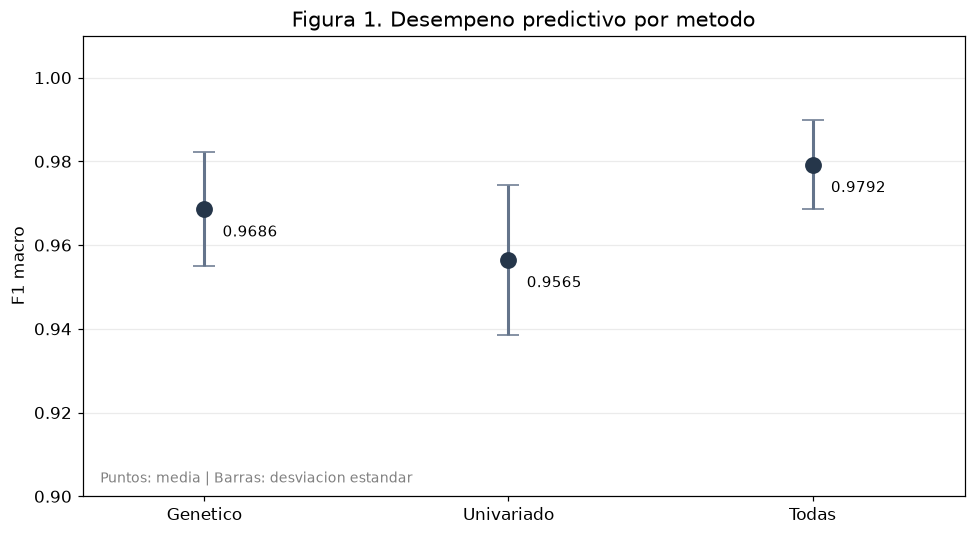

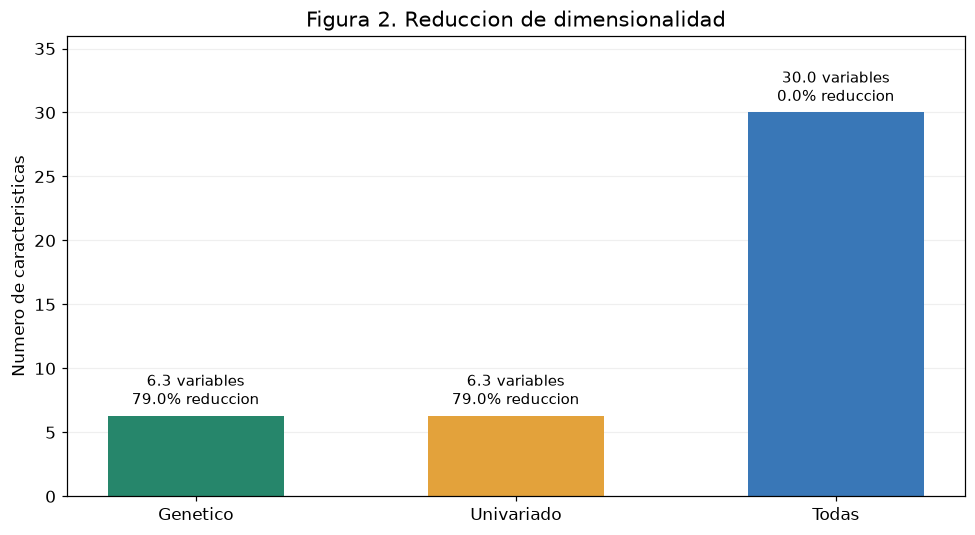

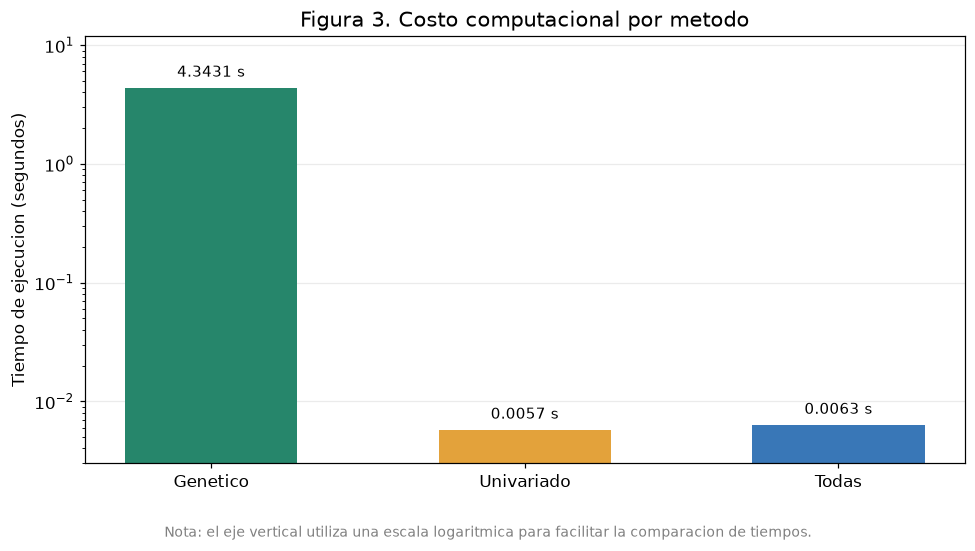

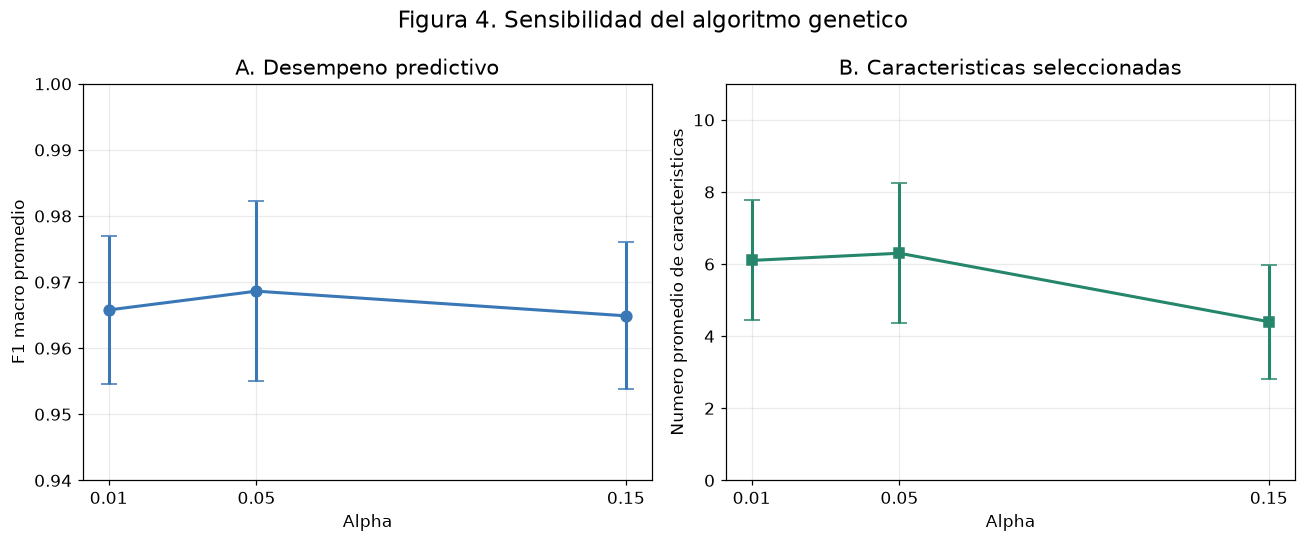

Figuras 1 a 4 generadas correctamente.


In [27]:

# ============================================================
# 9.1 VISUALIZACIONES: DESEMPENO Y EFICIENCIA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

carpeta_resultados = Path("resultados_tema9")
carpeta_graficos = carpeta_resultados / "graficos"
carpeta_graficos.mkdir(parents=True, exist_ok=True)

# Cargar los resultados
base = pd.read_csv(
    carpeta_resultados / "experimento_base.csv"
)

sens = pd.read_csv(
    carpeta_resultados / "sensibilidad_completa.csv"
)

# Clasificar los metodos
def clasificar_metodo(nombre):
    if nombre.startswith("AG_alpha_"):
        return "Genetico"
    elif nombre.startswith("Univariada_"):
        return "Univariado"
    elif nombre == "Todas_las_variables":
        return "Todas"
    raise ValueError(f"Metodo desconocido: {nombre}")

base["tipo_metodo"] = base["metodo"].apply(clasificar_metodo)

orden = ["Genetico", "Univariado", "Todas"]

colores = {
    "Genetico": "#26866B",
    "Univariado": "#E3A23B",
    "Todas": "#3977B7"
}

# Estadisticas principales
res = base.groupby("tipo_metodo").agg(
    f1_media=("metrica_principal", "mean"),
    f1_std=("metrica_principal", "std"),
    variables=("num_variables", "mean"),
    tiempo=("tiempo_s", "mean")
).loc[orden]

# Estilo general
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "savefig.bbox": "tight"
})

# ------------------------------------------------------------
# FIGURA 1: F1 MACRO CON DESVIACION ESTANDAR
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(orden))
medias = res["f1_media"].values
desviaciones = res["f1_std"].values

ax.errorbar(
    x,
    medias,
    yerr=desviaciones,
    fmt="o",
    markersize=10,
    capsize=7,
    linewidth=2,
    color="#25364A",
    ecolor="#64748B"
)

for i, valor in enumerate(medias):
    ax.annotate(
        f"{valor:.4f}",
        (i, valor),
        xytext=(12, -18),
        textcoords="offset points",
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(orden)
ax.set_ylabel("F1 macro")
ax.set_title("Figura 1. Desempeno predictivo por metodo")
ax.set_ylim(0.90, 1.01)
ax.set_xlim(-0.4, 2.5)
ax.grid(axis="y", alpha=0.25)

ax.text(
    0.02, 0.03,
    "Puntos: media | Barras: desviacion estandar",
    transform=ax.transAxes,
    fontsize=9,
    color="gray"
)

plt.tight_layout()
plt.savefig(carpeta_graficos / "01_f1_metodos.png", dpi=220)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURA 2: CARACTERISTICAS Y REDUCCION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

valores = res["variables"].values
barras = ax.bar(
    orden,
    valores,
    color=[colores[m] for m in orden],
    width=0.55
)

for barra, valor in zip(barras, valores):
    reduccion = (1 - valor / 30) * 100

    etiqueta = (
        f"{valor:.1f} variables\n"
        f"{reduccion:.1f}% reduccion"
    )

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.5,
        etiqueta,
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_ylabel("Numero de caracteristicas")
ax.set_title("Figura 2. Reduccion de dimensionalidad")
ax.set_ylim(0, 36)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(carpeta_graficos / "02_variables.png", dpi=220)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURA 3: TIEMPOS DE EJECUCION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

tiempos = res["tiempo"].values

barras = ax.bar(
    orden,
    tiempos,
    color=[colores[m] for m in orden],
    width=0.55
)

ax.set_yscale("log")
ax.set_ylim(0.003, 12)
ax.set_ylabel("Tiempo de ejecucion (segundos)")
ax.set_title("Figura 3. Costo computacional por metodo")
ax.grid(axis="y", which="major", alpha=0.25)
ax.set_axisbelow(True)

for barra, valor in zip(barras, tiempos):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor * 1.25,
        f"{valor:.4f} s",
        ha="center",
        fontsize=10
    )




# Nota explicativa debajo del grafico
fig.text(
    0.5, 0.01,
    "Nota: el eje vertical utiliza una escala logaritmica "
    "para facilitar la comparacion de tiempos.",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    carpeta_graficos / "03_tiempos.png",
    dpi=220
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURA 4: SENSIBILIDAD DE ALPHA (DOS PANELES)
# ------------------------------------------------------------

res_alpha = sens.groupby("alpha").agg(
    f1=("metrica_principal", "mean"),
    f1_std=("metrica_principal", "std"),
    variables=("num_variables", "mean"),
    variables_std=("num_variables", "std")
).sort_index()

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# Panel A: F1 macro
ax1.errorbar(
    res_alpha.index,
    res_alpha["f1"],
    yerr=res_alpha["f1_std"],
    fmt="o-",
    markersize=7,
    capsize=5,
    linewidth=2,
    color="#3977B7"
)

ax1.set_title("A. Desempeno predictivo")
ax1.set_xlabel("Alpha")
ax1.set_ylabel("F1 macro promedio")
ax1.set_ylim(0.94, 1.0)
ax1.set_xticks(res_alpha.index)
ax1.grid(alpha=0.25)

# Panel B: numero de variables
ax2.errorbar(
    res_alpha.index,
    res_alpha["variables"],
    yerr=res_alpha["variables_std"],
    fmt="s-",
    markersize=7,
    capsize=5,
    linewidth=2,
    color="#26866B"
)

ax2.set_title("B. Caracteristicas seleccionadas")
ax2.set_xlabel("Alpha")
ax2.set_ylabel("Numero promedio de caracteristicas")
ax2.set_ylim(0, 11)
ax2.set_xticks(res_alpha.index)
ax2.grid(alpha=0.25)

fig.suptitle(
    "Figura 4. Sensibilidad del algoritmo genetico",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    carpeta_graficos / "04_sensibilidad.png",
    dpi=220
)
plt.show()
plt.close(fig)

print("Figuras 1 a 4 generadas correctamente.")


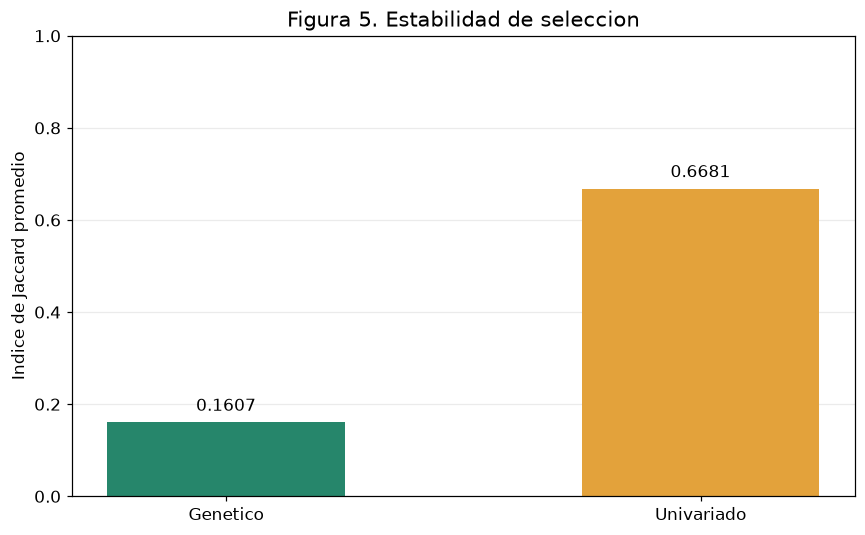

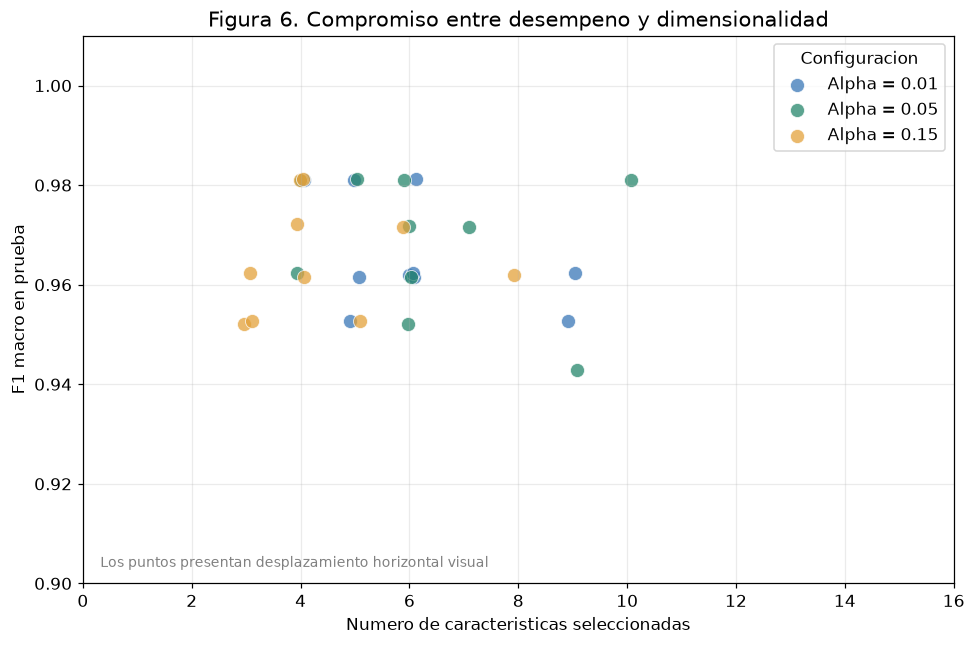

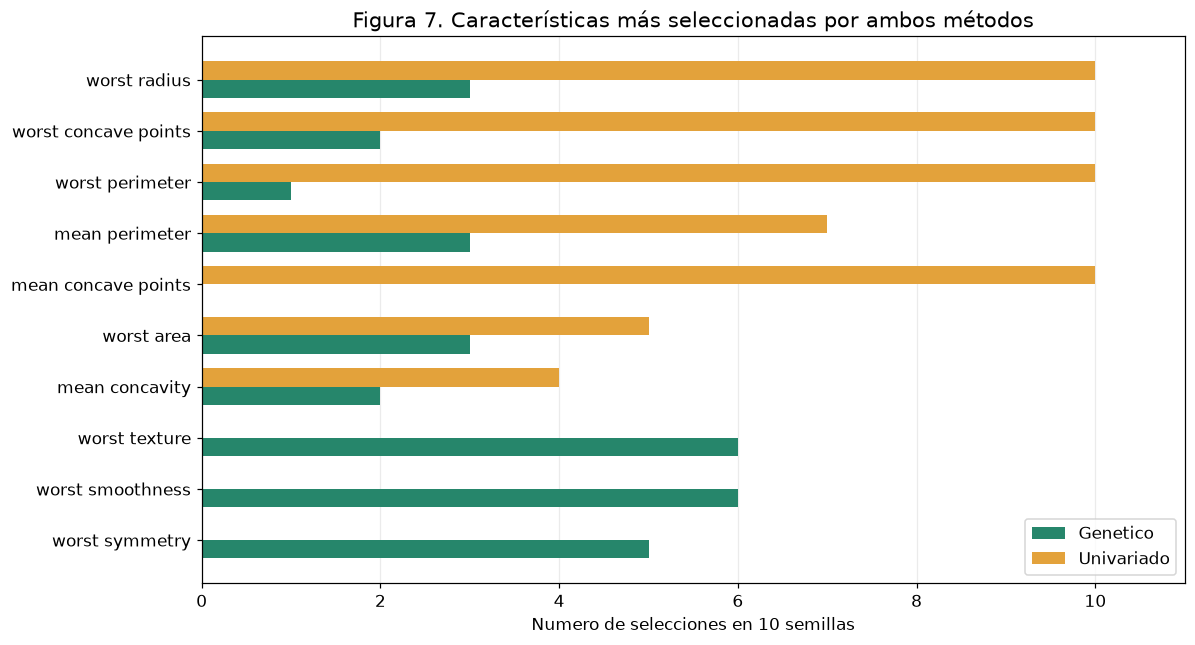

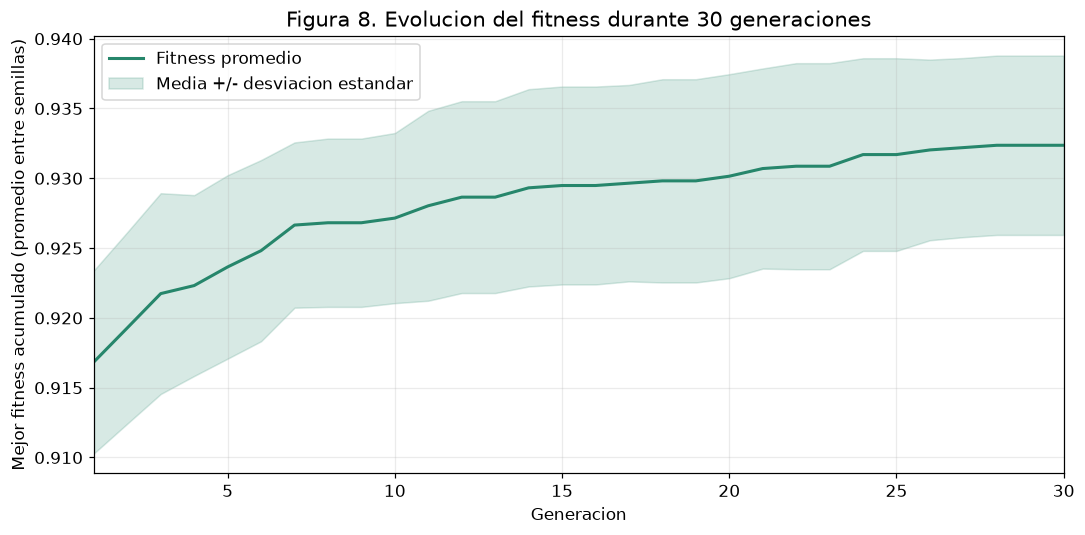

Figuras 5 a 8 generadas correctamente.
Todas las figuras estan en: resultados_tema9\graficos


In [24]:

# ============================================================
# 9.2 VISUALIZACIONES: ESTABILIDAD Y EVOLUCION
# ============================================================

# ------------------------------------------------------------
# FIGURA 5: ESTABILIDAD JACCARD
# ------------------------------------------------------------

estabilidad = pd.read_csv(
    carpeta_resultados / "estabilidad_jaccard.csv"
)

estabilidad["metodo_corto"] = estabilidad["metodo"].apply(
    lambda m: "Genetico" if "genet" in m.lower()
    else "Univariado"
)

estabilidad = estabilidad.set_index("metodo_corto")

metodos = ["Genetico", "Univariado"]
valores = estabilidad.loc[
    metodos, "jaccard_promedio"
].values

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    metodos,
    valores,
    color=[colores[m] for m in metodos],
    width=0.5
)

for barra, valor in zip(barras, valores):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.025,
        f"{valor:.4f}",
        ha="center",
        fontsize=11
    )

ax.set_ylim(0, 1)
ax.set_ylabel("Indice de Jaccard promedio")
ax.set_title("Figura 5. Estabilidad de seleccion")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    carpeta_graficos / "05_estabilidad_jaccard.png",
    dpi=220
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# # FIGURA 6: DISPERSION CON JITTER REPRODUCIBLE
# ------------------------------------------------------------
colores_alpha = {
    0.01: "#3977B7",
    0.05: "#26866B",
    0.15: "#E3A23B"
}

fig, ax = plt.subplots(figsize=(9, 6))

rng_grafico = np.random.default_rng(42)

for alpha in sorted(sens["alpha"].unique()):

    datos_alpha = sens[
        np.isclose(sens["alpha"], alpha)
    ]

    desplazamiento = rng_grafico.uniform(
        -0.12,
        0.12,
        size=len(datos_alpha)
    )

    ax.scatter(
        datos_alpha["num_variables"] + desplazamiento,
        datos_alpha["metrica_principal"],
        s=85,
        alpha=0.75,
        color=colores_alpha[round(float(alpha), 2)],
        label=f"Alpha = {alpha:.2f}",
        edgecolors="white",
        linewidths=0.6
    )

ax.set_xlabel("Numero de caracteristicas seleccionadas")
ax.set_ylabel("F1 macro en prueba")

ax.set_title(
    "Figura 6. Compromiso entre desempeno y dimensionalidad"
)

ax.set_xlim(0, 16)
ax.set_ylim(0.90, 1.01)
ax.set_xticks(range(0, 17, 2))
ax.grid(alpha=0.25)
ax.legend(title="Configuracion")

ax.text(
    0.02, 0.03,
    "Los puntos presentan desplazamiento horizontal visual",
    transform=ax.transAxes,
    fontsize=9,
    color="gray"
)

plt.tight_layout()
plt.savefig(
    carpeta_graficos / "06_dispersion_f1_variables.png",
    dpi=220
)
plt.show()
plt.close(fig)
# ------------------------------------------------------------
# FIGURA 7: Características más seleccionadas por ambos métodos
# ------------------------------------------------------------

frecuencias = pd.read_csv(
    carpeta_resultados / "frecuencia_caracteristicas.csv"
)

frecuencias["frecuencia_total"] = (
    frecuencias["frecuencia_ag"] +
    frecuencias["frecuencia_univariada"]
)

top10 = (
    frecuencias
    .sort_values("frecuencia_total", ascending=False)
    .head(10)
    .sort_values("frecuencia_total")
)

fig, ax = plt.subplots(figsize=(11, 6))

y = np.arange(len(top10))
ancho = 0.36

ax.barh(
    y - ancho / 2,
    top10["frecuencia_ag"],
    height=ancho,
    label="Genetico",
    color=colores["Genetico"]
)

ax.barh(
    y + ancho / 2,
    top10["frecuencia_univariada"],
    height=ancho,
    label="Univariado",
    color=colores["Univariado"]
)

ax.set_yticks(y)
ax.set_yticklabels(top10["caracteristica"])
ax.set_xlim(0, 11)
ax.set_xlabel("Numero de selecciones en 10 semillas")
ax.set_title(
    "Figura 7. Características más seleccionadas por ambos métodos"
)
ax.legend()
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    carpeta_graficos / "07_frecuencia_caracteristicas.png",
    dpi=220
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURA 8: CONVERGENCIA DEL ALGORITMO GENETICO
# ------------------------------------------------------------

historiales = []

for semilla in range(10):

    ruta = carpeta_resultados / (
        f"detalles_semilla_{semilla}.npz"
    )

    if not ruta.exists():
        raise FileNotFoundError(
            f"Falta el historial para la semilla {semilla}: {ruta}"
        )

    with np.load(ruta) as archivo:
        historial = archivo["historial_aptitud"].astype(float)

    historiales.append(historial)

# Verificar que todos tienen la misma longitud
longitudes = [len(h) for h in historiales]

assert len(set(longitudes)) == 1, (
    "Los historiales tienen distintas longitudes"
)

matriz_historiales = np.vstack(historiales)

media_fitness = matriz_historiales.mean(axis=0)
std_fitness = matriz_historiales.std(axis=0, ddof=1)

generaciones = np.arange(1, len(media_fitness) + 1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    generaciones,
    media_fitness,
    linewidth=2,
    color=colores["Genetico"],
    label="Fitness promedio"
)

ax.fill_between(
    generaciones,
    media_fitness - std_fitness,
    media_fitness + std_fitness,
    color=colores["Genetico"],
    alpha=0.18,
    label="Media +/- desviacion estandar"
)

ax.set_xlabel("Generacion")
ax.set_ylabel("Mejor fitness acumulado (promedio entre semillas)")
ax.set_title(
    "Figura 8. Evolucion del fitness durante 30 generaciones"
)

ax.set_xlim(1, len(generaciones))
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig(
    carpeta_graficos / "08_convergencia_genetica.png",
    dpi=220
)
plt.show()
plt.close(fig)

print("Figuras 5 a 8 generadas correctamente.")
print("Todas las figuras estan en:", carpeta_graficos)



## 10. Discusión de resultados

### 10.1. Reducción de dimensionalidad y desempeño predictivo

Los experimentos realizados permiten analizar la viabilidad de utilizar algoritmos genéticos para seleccionar subconjuntos de características que equilibren la calidad predictiva y la simplicidad del modelo.

Con la configuración principal ($\alpha = 0.05$), el algoritmo genético seleccionó en promedio **6.3 de las 30 características originales**, lo que representa una reducción del **79 %**.

A pesar de esta disminución, el clasificador alcanzó un F1 macro promedio de **0.9686**, mientras que el modelo que utilizó todas las características obtuvo **0.9792**.

La diferencia promedio de aproximadamente **0.0106** indica que la reducción de dimensionalidad estuvo acompañada de una pérdida relativamente pequeña del rendimiento predictivo en el conjunto de datos estudiado.

Este resultado respalda parcialmente la hipótesis de investigación: es posible obtener subconjuntos considerablemente más pequeños conservando un desempeño predictivo cercano al modelo original.

Sin embargo, no se puede afirmar que el método mantuvo exactamente el mismo rendimiento, debido a que el modelo completo obtuvo un F1 macro promedio superior.

### 10.2. Comparación entre selección evolutiva y univariada

Una de las comparaciones centrales del estudio consiste en evaluar el algoritmo genético frente al método univariado SelectKBest.

Para garantizar una comparación equilibrada en términos de dimensionalidad, ambos métodos utilizaron el mismo número de características en cada semilla.

Los resultados muestran que:

- El algoritmo genético obtuvo un F1 macro promedio de **0.9686**.
- SelectKBest obtuvo un F1 macro promedio de **0.9565**.
- La diferencia media fue de aproximadamente **0.0121** a favor del algoritmo genético.
- El algoritmo genético superó al método univariado en **8 de las 10 semillas**.

Esta diferencia puede relacionarse con los procedimientos de selección empleados.

SelectKBest utiliza un criterio estadístico univariado, evaluando cada característica individualmente mediante ANOVA F.

Por el contrario, el algoritmo genético utiliza un enfoque *wrapper*, evaluando combinaciones completas de características según el rendimiento del clasificador sobre los datos de validación.

Esto permite que la búsqueda evolutiva considere el comportamiento predictivo conjunto de las variables seleccionadas, en lugar de depender exclusivamente de sus puntuaciones individuales.

Los resultados son compatibles con una posible ventaja del enfoque evolutivo para encontrar combinaciones predictivamente favorables.

No obstante, las diferencias observadas son descriptivas y no constituyen por sí mismas evidencia de superioridad estadísticamente significativa.

### 10.3. Costo computacional de la búsqueda evolutiva

El principal inconveniente del algoritmo genético fue su mayor costo computacional.

En el experimento principal se registraron los siguientes tiempos promedio:

| Método | Tiempo promedio |
|---|---:|
| Algoritmo genético | 4.3431 s |
| Selección univariada | 0.0057 s |
| Todas las características | 0.0063 s |

El algoritmo genético requirió aproximadamente **760 veces más tiempo** que el método univariado.

Esta diferencia se explica por el procedimiento de búsqueda evolutiva, que necesita evaluar numerosos subconjuntos mediante entrenamientos sucesivos del clasificador.

En cambio, SelectKBest calcula puntuaciones estadísticas para seleccionar características sin explorar iterativamente cientos de combinaciones mediante el clasificador.

Por tanto, aunque el algoritmo genético obtuvo un F1 macro promedio superior al método univariado, dicha ventaja estuvo acompañada de un incremento considerable en el tiempo de selección.

Esto representa un compromiso importante: el enfoque evolutivo puede resultar útil cuando se prioriza la calidad del subconjunto encontrado, mientras que los métodos univariados pueden ser preferibles cuando el tiempo de procesamiento constituye una restricción importante.

Debe considerarse que los tiempos corresponden al entorno y las condiciones de ejecución utilizados, por lo que no representan tiempos universales de los algoritmos.

### 10.4. Estabilidad de las características seleccionadas

La estabilidad constituye otro criterio importante para evaluar los procedimientos de selección de características.

En este estudio se utilizó el índice de Jaccard para medir la similitud entre los subconjuntos seleccionados durante las diez ejecuciones.

Los resultados fueron:

- **Algoritmo genético:** Jaccard promedio de 0.1607.
- **Selección univariada:** Jaccard promedio de 0.6681.

Estos valores indican que SelectKBest produjo subconjuntos considerablemente más similares entre ejecuciones.

En contraste, el algoritmo genético seleccionó combinaciones de características más variables.

Una posible explicación es la naturaleza estocástica del algoritmo genético, debido a que la inicialización, selección, cruce y mutación introducen aleatoriedad durante la búsqueda.

Otra explicación posible es la presencia de características redundantes o de diferentes combinaciones capaces de obtener rendimientos predictivos semejantes.

Sin embargo, estas explicaciones no fueron evaluadas individualmente en el experimento y deben considerarse hipótesis interpretativas.

Además, las diez semillas modificaron tanto las particiones de entrenamiento como las decisiones aleatorias del algoritmo genético. En consecuencia, la estabilidad medida refleja la variabilidad del procedimiento completo.

La baja estabilidad representa una limitación cuando se requiere identificar un conjunto consistente de características. No obstante, no implica necesariamente un bajo desempeño predictivo.

### 10.5. Influencia del parámetro alpha

El análisis de sensibilidad permitió estudiar cómo cambia el comportamiento del algoritmo genético al modificar la penalización por número de características.

Se evaluaron tres configuraciones de la función fitness:

$$
Fitness(m)=(1-\alpha)F1_{\mathrm{macro,val}}(m)
-\alpha\frac{k}{d}
$$

Los resultados promedio fueron:

| Alpha | F1 macro | Características | Reducción |
|---|---:|---:|---:|
| 0.01 | 0.9658 | 6.1 | 79.7 % |
| 0.05 | 0.9686 | 6.3 | 79.0 % |
| 0.15 | 0.9649 | 4.4 | 85.3 % |

La configuración $\alpha = 0.05$ obtuvo el mayor F1 macro promedio de las tres configuraciones estudiadas.

Por otra parte, $\alpha = 0.15$ favoreció subconjuntos más pequeños, seleccionando únicamente 4.4 características en promedio.

Esto corresponde a una reducción del 85.3 % respecto a las 30 variables originales, con una disminución del F1 macro promedio de aproximadamente 0.0037 respecto a la configuración principal.

La comparación muestra que el parámetro alpha permite modificar el equilibrio entre desempeño predictivo y simplicidad.

Sin embargo, el comportamiento no fue estrictamente monotónico: con alpha = 0.01 se seleccionaron ligeramente menos características que con alpha = 0.05.

Esto puede relacionarse con la naturaleza estocástica del proceso de búsqueda y con la interacción entre la calidad predictiva y la penalización incorporada en la función fitness.

En consecuencia, aumentar alpha favorece relativamente la reducción de características dentro del objetivo de optimización, pero no garantiza que todas las ejecuciones produzcan subconjuntos progresivamente más pequeños.

### 10.6. Comportamiento evolutivo y convergencia

La Figura 8 muestra la evolución del mejor fitness acumulado durante las 30 generaciones del algoritmo genético, utilizando la configuración principal.

Se observa un incremento del fitness promedio desde aproximadamente **0.917** al inicio hasta **0.932** al finalizar las generaciones.

Las mejoras fueron más pronunciadas durante las primeras generaciones y posteriormente se observaron incrementos menores, con algunos periodos de estabilización.

Este comportamiento es compatible con el funcionamiento de una búsqueda evolutiva con elitismo, que conserva las mejores soluciones encontradas.

La banda de desviación estándar muestra que existen diferencias en los niveles de fitness alcanzados por las distintas semillas.

Aunque la tendencia sugiere una estabilización progresiva de las soluciones, no demuestra que se haya alcanzado el óptimo global.

### 10.7. Interpretación integral

Considerando conjuntamente los resultados, el algoritmo genético presentó ventajas y limitaciones frente a los métodos de referencia.

Su principal aporte fue encontrar subconjuntos pequeños de características con un desempeño predictivo relativamente cercano al modelo completo y superior, en promedio, al método univariado cuando ambos utilizaron el mismo número de variables.

Sin embargo, esta ventaja estuvo acompañada de un mayor costo computacional y una menor estabilidad de las características seleccionadas.

El modelo con todas las características obtuvo el mayor F1 macro promedio, mientras que SelectKBest presentó ventajas en rapidez y consistencia.

Por tanto, los resultados no permiten identificar un método universalmente superior en todos los criterios estudiados.

La elección del procedimiento de selección dependerá de los objetivos del problema, la importancia de reducir características, el desempeño predictivo requerido, el costo computacional aceptable y la necesidad de obtener subconjuntos estables.

En el escenario experimental evaluado, la selección evolutiva constituye una alternativa viable para reducir dimensionalidad, pero sus beneficios deben valorarse conjuntamente con sus limitaciones.



## 11. Conclusiones

La investigación permitió evaluar la selección evolutiva de características mediante un algoritmo genético binario, comparando su comportamiento con la selección univariada y con un clasificador que utiliza todas las variables originales.

A partir de los experimentos realizados, se establecen las siguientes conclusiones:

**1. La selección evolutiva permitió reducir considerablemente la dimensionalidad.**

Con la configuración principal ($\alpha = 0.05$), el algoritmo genético seleccionó en promedio 6.3 de las 30 características disponibles, lo que equivale a una reducción del 79 %. Esto demuestra que fue posible encontrar subconjuntos significativamente más pequeños en términos de cantidad de variables, sin necesidad de utilizar todas las características originales.

**2. El desempeño predictivo se mantuvo relativamente cercano al modelo completo.**

El algoritmo genético obtuvo un F1 macro promedio de 0.9686, frente a 0.9792 del clasificador con todas las características. La diferencia de aproximadamente 0.0106 indica que la reducción de dimensionalidad produjo una pérdida media relativamente pequeña de desempeño en el escenario evaluado.

Por tanto, los resultados respaldan la hipótesis de que es posible reducir una parte considerable de las características conservando un rendimiento predictivo cercano al modelo de referencia.

**3. El algoritmo genético superó en promedio a la selección univariada con igual número de características.**

El método evolutivo alcanzó un F1 macro promedio de 0.9686, mientras que SelectKBest obtuvo 0.9565. Además, el algoritmo genético presentó un mayor F1 en ocho de las diez semillas.

Esto sugiere que la evaluación de combinaciones completas de características mediante un enfoque *wrapper* puede ofrecer ventajas predictivas frente a la selección basada en puntuaciones individuales.

Sin embargo, esta diferencia descriptiva no establece por sí sola una superioridad estadísticamente significativa.

**4. La mejora predictiva estuvo acompañada de un mayor costo computacional y menor estabilidad.**

El algoritmo genético necesitó aproximadamente 4.34 segundos por ejecución, frente a unos 0.0057 segundos de la selección univariada.

Asimismo, presentó un índice de Jaccard promedio de 0.1607, considerablemente inferior al 0.6681 obtenido por SelectKBest.

Por tanto, aunque el método evolutivo obtuvo mejores resultados predictivos en promedio, fue más costoso y seleccionó subconjuntos menos consistentes entre ejecuciones.

**5. El parámetro alpha permitió modificar el equilibrio entre desempeño y simplicidad.**

El análisis de sensibilidad mostró que $\alpha = 0.15$ favoreció subconjuntos más pequeños, utilizando en promedio 4.4 características, equivalente a una reducción del 85.3 %.

Esta configuración obtuvo un F1 macro promedio de 0.9649, ligeramente inferior al 0.9686 alcanzado con $\alpha = 0.05$.

Los resultados evidencian que la penalización por número de características permite orientar la búsqueda hacia soluciones más compactas, aunque puede afectar el desempeño predictivo.

### Conclusión general

Los resultados demuestran que la selección evolutiva mediante algoritmos genéticos constituye una alternativa viable para reducir la cantidad de características utilizadas por un clasificador, manteniendo un desempeño predictivo relativamente cercano al modelo completo.

No obstante, su conveniencia debe evaluarse considerando conjuntamente la calidad predictiva, el número de características, el costo computacional y la estabilidad de selección.

En el contexto experimental estudiado, el algoritmo genético ofreció un mejor F1 macro promedio que la selección univariada con igual número de variables, pero no superó al modelo completo en desempeño predictivo y presentó limitaciones importantes de tiempo y estabilidad.

Estas conclusiones corresponden al conjunto de datos Breast Cancer Wisconsin (Diagnostic), al clasificador de regresión logística y a las configuraciones evaluadas; no representan una superioridad universal del enfoque evolutivo.



## 12. Limitaciones y trabajo futuro

### 12.1. Limitaciones del estudio

A pesar de los resultados obtenidos, la investigación presenta limitaciones que deben considerarse al interpretar sus conclusiones.

**1. Evaluación sobre un único conjunto de datos.**

El estudio utilizó exclusivamente el conjunto Breast Cancer Wisconsin (Diagnostic), con 569 observaciones y 30 características numéricas.

Por tanto, los resultados no pueden generalizarse directamente a problemas con mayor dimensionalidad, diferentes distribuciones de datos o distintas tareas de clasificación.

**2. Uso de un solo clasificador.**

Se utilizó regresión logística como clasificador fijo para aislar el efecto de la selección de características.

Esta decisión permitió realizar una comparación controlada, pero no permite determinar si el algoritmo genético produciría resultados similares con árboles de decisión, máquinas de vectores de soporte o redes neuronales.

**3. Número limitado de ejecuciones.**

Se realizaron diez ejecuciones por configuración, lo que permitió analizar medias, desviaciones estándar y estabilidad.

Sin embargo, este número constituye una muestra limitada de ejecuciones y los resultados se analizaron principalmente mediante estadística descriptiva.

No se estableció una prueba concluyente de superioridad estadística entre los métodos.

**4. Variabilidad de las particiones y del algoritmo genético.**

Cada semilla modificó tanto la división de los datos como las decisiones aleatorias de la búsqueda evolutiva.

Por esta razón, la variabilidad observada refleja ambos factores y no permite distinguir completamente el efecto de la partición de los datos del efecto de la aleatoriedad del algoritmo genético.

**5. Baja estabilidad de las características seleccionadas.**

El algoritmo genético obtuvo un índice de Jaccard promedio de 0.1607, lo que evidencia una baja similitud entre los subconjuntos seleccionados durante las ejecuciones.

Esta variabilidad puede limitar su utilidad cuando se requiere identificar un conjunto consistente de variables para su interpretación posterior.

**6. Configuración evolutiva limitada.**

Se utilizó una población de 30 individuos, 30 generaciones y parámetros predefinidos de selección, cruce y mutación.

El análisis de sensibilidad se concentró en tres valores de alpha, sin estudiar exhaustivamente los demás hiperparámetros.

En consecuencia, no puede asegurarse que la configuración utilizada sea óptima.

**7. Evaluación con particiones fijas por semilla.**

La selección evolutiva utilizó un conjunto de validación para evaluar los subconjuntos candidatos.

Aunque el conjunto de prueba se mantuvo fuera del proceso de optimización del fitness, no se implementó validación cruzada anidada.

Esto limita el alcance de las conclusiones sobre generalización y selección de hiperparámetros.

**8. Alcance académico de la aplicación.**

El conjunto de datos proviene de un problema de clasificación médica, pero el objetivo de esta investigación fue comparar métodos computacionales.

Los resultados no constituyen una validación clínica y no deben interpretarse como evidencia suficiente para utilizar el clasificador en decisiones médicas reales.

### 12.2. Trabajo futuro

A partir de las limitaciones identificadas, se proponen las siguientes líneas de investigación:

**1. Evaluación con otros datasets.**

Aplicar el algoritmo genético a conjuntos de datos con diferentes cantidades de características, tamaños de muestra y niveles de redundancia, para comprobar si los resultados se mantienen en otros escenarios.

**2. Comparación con diferentes clasificadores.**

Estudiar la selección evolutiva utilizando clasificadores como Random Forest, máquinas de vectores de soporte y redes neuronales, manteniendo protocolos de evaluación comparables.

**3. Mejora de la estabilidad.**

Investigar estrategias para favorecer la selección de subconjuntos más consistentes, como métodos de consenso, selección basada en frecuencias o modificaciones de la función fitness que consideren estabilidad.

**4. Optimización multiobjetivo.**

Explorar algoritmos como NSGA-II, que permitan optimizar simultáneamente el desempeño predictivo y la cantidad de características, obteniendo diferentes soluciones de compromiso en lugar de combinar ambos criterios mediante un único parámetro alpha.

**5. Análisis de hiperparámetros evolutivos.**

Evaluar el efecto del tamaño de la población, número de generaciones, probabilidad de cruce y tasa de mutación sobre el rendimiento, el costo computacional y la estabilidad.

**6. Evaluación estadística más amplia.**

Incrementar el número de ejecuciones y utilizar procedimientos estadísticos apropiados para comparar los métodos, complementando las medias y desviaciones estándar con estimaciones de incertidumbre.

**7. Protocolos de validación más rigurosos.**

Implementar validación cruzada anidada y separar las fuentes de aleatoriedad asociadas a las particiones y a la búsqueda genética, para obtener estimaciones más robustas del desempeño y la estabilidad.

### 12.3. Cierre

La investigación permitió comprobar experimentalmente que los algoritmos genéticos pueden utilizarse como herramientas de selección de características, reduciendo considerablemente la dimensionalidad mientras conservan un desempeño predictivo elevado.

Al mismo tiempo, los resultados mostraron que la calidad de una solución no debe evaluarse únicamente mediante su precisión predictiva, sino también mediante criterios de simplicidad, estabilidad, costo computacional y capacidad de generalización.
